本页集中展示理论章中的基础抽样与四个案例，适合课堂查看保存的结果，也可以在本地从头运行。各节标题与理论正文对应，点击每个案例开头的链接即可返回相应位置。

## 阅读与运行说明 {.unnumbered #sec-mc-nb-guide}

从仓库根目录或本页所在目录启动 Jupyter，依次运行所有单元。所需环境包括 NumPy、pandas、Matplotlib、SciPy 和 statsmodels。公共设置只需运行一次，各案例随后设置自己的参数与随机数发生器。不要在没有初始化的情况下直接执行某个中间单元。

案例一、二、四使用教学模拟，不需要外部数据。案例三读取仓库 `data/monte-carlo/` 下已保存的处理后数据，不联网取数，也不读取教师本机的供应商缓存。运行结果默认写入仓库 `output/monte-carlo/cases/`，不会覆盖输入数据。

网页展示预先执行的输出，Quarto 编译不执行计算。补充核验在网页中折叠，Notebook 文件仍保留完整代码。本文使用案例一至四定位内容，不占用全书正式章节编号。

In [1]:
from pathlib import Path
from math import log, sqrt, exp, erf
import json
import os
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
import statsmodels.api as sm
from statsmodels.sandbox.regression.gmm import IV2SLS
from IPython.display import display, Image

def find_course_root():
    # 根据课程数据与目录识别仓库，不依赖本机绝对路径。
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if ((candidate / 'data/monte-carlo/returns.csv').is_file()
                and (candidate / 'notebooks/monte-carlo').is_dir()):
            return candidate
    raise FileNotFoundError('请在完整课程仓库内启动；需要 data/monte-carlo/returns.csv。')

ROOT = find_course_root()
OUTPUT = Path(os.environ.get('FINECO_MC_OUTPUT', ROOT / 'output/monte-carlo/cases'))
OUTPUT.mkdir(parents=True, exist_ok=True)
SEED = 20261001
plt.rcParams.update({'font.family': 'sans-serif',
                     'font.sans-serif': ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'DejaVu Sans'],
                     'axes.unicode_minus': False, 'font.size': 11})
pd.set_option('display.max_columns', 16)
pd.set_option('display.width', 140)
case_results = {}
display(pd.Series({'Python': platform.python_version(), 'NumPy': np.__version__,
                   'pandas': pd.__version__, '主随机种子': SEED}, name='运行环境'))

Python     3.11.14
NumPy        2.4.2
pandas       2.3.3
主随机种子     20261001
Name: 运行环境, dtype: object

## 基础抽样与模拟设置 {.unnumbered #sec-mc-nb-basics}

[返回正文：几个基本概念](../../lectures/monte-carlo.qmd#sec-mc-basics)。

### 随机数、概率分布与抽样 {.unnumbered}

$U\sim U(0,1)$ 表示随机变量 $U$ 服从区间 $(0,1)$ 上的均匀分布，符号 $\sim$ 读作服从。均匀分布在区间内具有相同的概率密度，等长子区间获得相同的概率。下面分别抽取均匀、标准正态和均值为 1 的指数随机数，观察取值范围、对称性和右尾的区别。

每幅图均包含 10000 个抽样值，纵轴为概率密度。它们用于说明如何从给定概率分布抽样，尚不是一个完整的回归或金融决策案例。

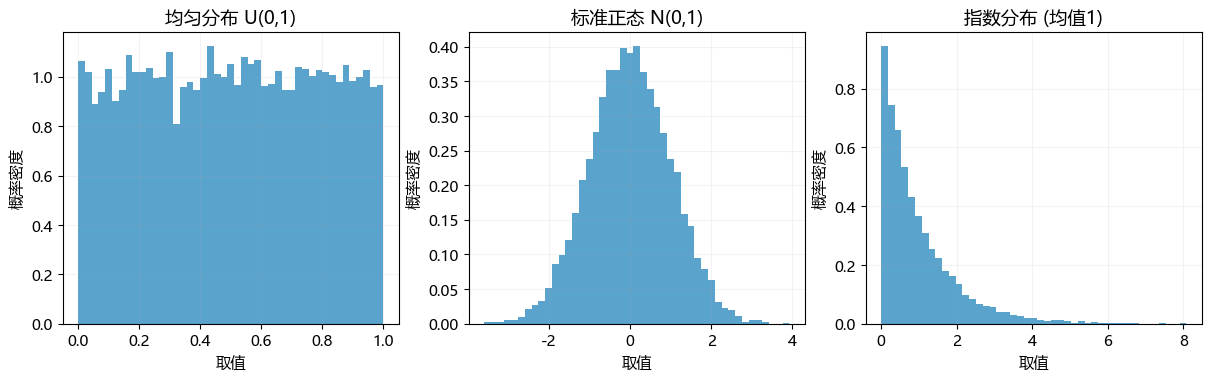

,样本均值,样本标准差
"均匀分布 U(0,1)",0.501337,0.287727
"标准正态 N(0,1)",-0.002022,1.003969
指数分布 (均值1),0.994185,0.994872


In [2]:
#| label: fig-mc-nb-three-distributions
#| fig-cap: "三种概率分布的抽样对照。各生成 10000 个值，保留各分布适合的横轴范围，不用图形宽度直接比较波动大小。"
distribution_rng = np.random.default_rng(SEED)
distribution_samples = {
    '均匀分布 U(0,1)': distribution_rng.uniform(size=10000),
    '标准正态 N(0,1)': distribution_rng.normal(size=10000),
    '指数分布 (均值1)': distribution_rng.exponential(scale=1, size=10000),
}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.7), layout='constrained')
for axis, (name, sample) in zip(axes, distribution_samples.items()):
    axis.hist(sample, bins=45, density=True, alpha=.65, color='#0072B2')
    axis.set(title=name, xlabel='取值', ylabel='概率密度')
    axis.grid(alpha=.15)
plt.show()
display(pd.DataFrame({name: {'样本均值': values.mean(), '样本标准差': values.std(ddof=1)}
                      for name, values in distribution_samples.items()}).T)

### 从均匀随机数到目标分布 {.unnumbered}

对具有可用逆函数的连续累积分布函数 $F$，可以令 $X=F^{-1}(U)$。例如，均值为 1 的指数分布满足 $F(x)=1-e^{-x}$，因此 $X=-\log(1-U)$。下一段直接用均匀随机数作变换。

这只是逆分布函数抽样的一个例子。不同分布也可以使用其他抽样算法，不能把这个变换直接套到所有分布上。软件完成数值抽样，但需要模拟哪些变量、采用何种分布、参数如何确定，仍应根据分析问题设定。

In [3]:
inverse_rng = np.random.default_rng(SEED)
uniform_values = inverse_rng.random(10000)
exponential_values = -np.log1p(-uniform_values)
assert np.isfinite(exponential_values).all() and (exponential_values >= 0).all()
display(pd.Series({'指数样本均值': exponential_values.mean(),
                   '指数样本标准差': exponential_values.std(ddof=1),
                   '理论均值': 1.0, '理论标准差': 1.0}))

指数样本均值     1.001571
指数样本标准差    1.002672
理论均值       1.000000
理论标准差      1.000000
dtype: float64

### 随机种子、DGP 与重复次数 {.unnumbered}

相同的发生器、种子和调用顺序可以产生相同序列。下面分别初始化两个发生器，比较它们生成的前五个标准正态数。

DGP 不仅包括分布，还包括变量之间的关系和依赖设定。案例一将完整演示如何生成解释变量、扰动项和因变量，并通过重复估计得到抽样分布。这里先区分：$n$ 是每次回归所用的样本量，$B$ 是重复生成样本并估计的次数。

In [4]:
rng1 = np.random.default_rng(12345)
rng2 = np.random.default_rng(12345)
a = rng1.normal(size=5)
b = rng2.normal(size=5)
pd.DataFrame({"run_1": a, "run_2": b, "same": a == b})

,run_1,run_2,same
0,-1.423825,-1.423825,True
1,1.263728,1.263728,True
2,-0.870662,-0.870662,True
3,-0.259173,-0.259173,True
4,-0.075343,-0.075343,True


::: {.callout-note collapse="true" title="补充核验：用模拟均值近似一个已知期望"}

设 $X\sim N(0,1)$，则 $E(X^{2})=1$。随着抽样数量增加，样本平方的平均值通常更接近该期望，单条随机序列不要求误差单调下降。

In [5]:
B_max = 100000
rng = np.random.default_rng(SEED)
x = rng.normal(size=B_max)
running_mean = np.cumsum(x**2) / np.arange(1, B_max + 1)
checkpoints = [10, 100, 1000, 10000, 100000]
pd.DataFrame({
    "B": checkpoints,
    "MC_estimate": [running_mean[b-1] for b in checkpoints],
    "error": [running_mean[b-1] - 1 for b in checkpoints],
})

,B,MC_estimate,error
0,10,1.073586,0.073586
1,100,1.060885,0.060885
2,1000,1.074883,0.074883
3,10000,0.991805,-0.008195
4,100000,1.000467,0.000467


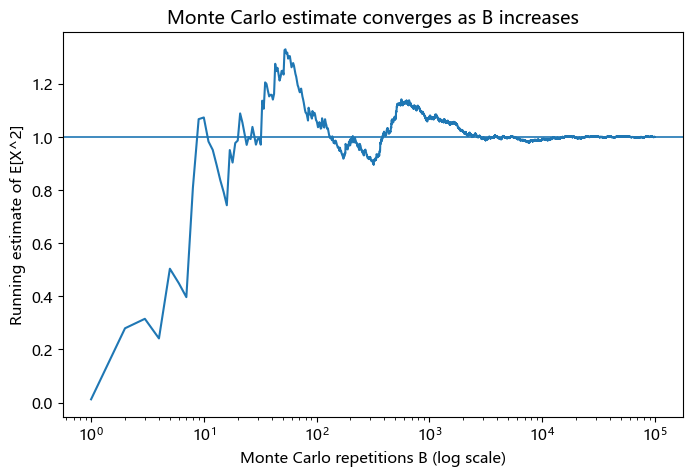

In [6]:
#| label: fig-mc-nb-running-mean
#| fig-cap: "标准正态平方的累计平均值与理论期望 1。"
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(np.arange(1, B_max + 1), running_mean)
ax.axhline(1.0, linewidth=1.2)
ax.set_xscale("log")
ax.set_xlabel("Monte Carlo repetitions B (log scale)")
ax.set_ylabel("Running estimate of E[X^2]")
ax.set_title("Monte Carlo estimate converges as B increases")
plt.show()

:::

## 案例一：用模拟理解计量性质 {.unnumbered #sec-mc-nb-econometrics}

[返回正文：案例一](../../lectures/monte-carlo.qmd#sec-mc-econometrics)。

本例在已知参数真值的 DGP 中比较估计结果。OLS 部分采用 $Y_{i}=1+2X_{i}+u_{i}$，解释变量与扰动项相互独立且均服从标准正态分布。每次都重新生成整个样本，再估计和保存斜率。

### OLS 的无偏性 {.unnumbered}

固定 $n=100$，重复 $B=5000$ 次。输出均值与真值 2 的差作为 MC 偏差，不能把一次估计或有限次均值当作无偏性的证明。

In [7]:
def ols_mc(n=100, B=5000, beta0=1.0, beta1=2.0, seed=SEED):
    rng = np.random.default_rng(seed)
    bhat = np.empty(B)

    for b in range(B):
        x = rng.normal(0, 1, n)
        u = rng.normal(0, 1, n)
        y = beta0 + beta1 * x + u

        X = sm.add_constant(x)
        fit = sm.OLS(y, X).fit()
        bhat[b] = fit.params[1]

    return bhat

bhat_100 = ols_mc(n=100, B=5000)
pd.Series({
    "true_beta": 2.0,
    "mean_beta_hat": bhat_100.mean(),
    "bias": bhat_100.mean() - 2.0,
    "empirical_sd": bhat_100.std(ddof=1),
})

true_beta        2.000000
mean_beta_hat    2.001526
bias             0.001526
empirical_sd     0.102839
dtype: float64

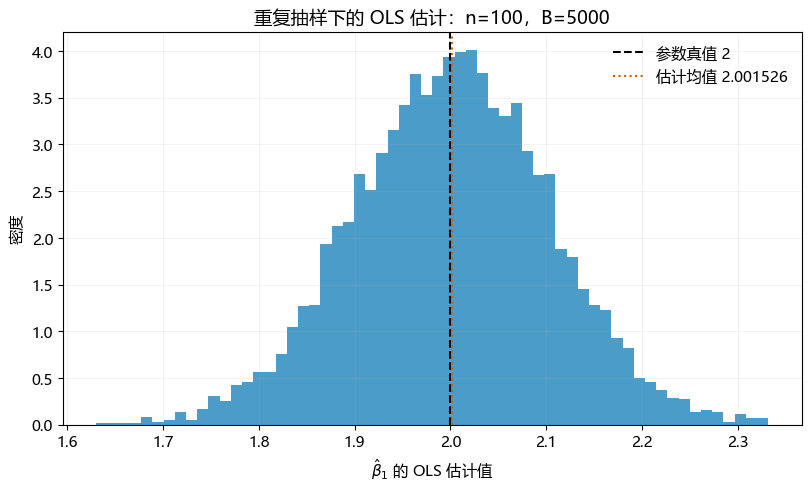

In [8]:
#| label: fig-mc-nb-ols-unbiased
#| fig-cap: "OLS 无偏性：估计分布、参数真值与 MC 均值。"
plt.rcParams.update({
    'font.family': 'Microsoft YaHei', 'font.size': 11,
    'axes.unicode_minus': False,
})
colors = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#666666']
line_styles = ['-', '--', '-.', ':', (0, (5, 1, 1, 1))]

# 无偏性：完整直方图与估计均值，不将单次估计等同于期望。
fig, axis = plt.subplots(figsize=(8, 4.8), layout='constrained')
axis.hist(bhat_100, bins=60, density=True, color=colors[0], alpha=.7)
axis.axvline(2, color='black', linestyle='--', label='参数真值 2')
axis.axvline(bhat_100.mean(), color=colors[1], linestyle=':',
             label=f'估计均值 {bhat_100.mean():.6f}')
axis.set(xlabel=r'$\hat{\beta}_{1}$ 的 OLS 估计值', ylabel='密度',
         title='重复抽样下的 OLS 估计：n=100，B=5000')
axis.legend(frameon=False)
axis.grid(alpha=.15)
plt.show()

按这些设定，保存结果中的估计均值约为 2.001526，与真值 2 接近。图中真值线应与估计分布共同观察。

### OLS 的一致性 {.unnumbered}

保持 DGP 不变，改变每次回归的样本量，各组重复 3000 次。左图比较估计分布，右图和表比较经验标准差。图形只使用统一显示窗口，没有将窗口外的估计值从统计量中删除。

In [9]:
sample_sizes = [20, 50, 100, 500, 2000]
ols_results = {}

for n in sample_sizes:
    vals = ols_mc(n=n, B=3000, seed=SEED + n)
    ols_results[n] = vals

ols_summary = pd.DataFrame([
    {
        "n": n,
        "mean_beta_hat": vals.mean(),
        "bias": vals.mean() - 2.0,
        "empirical_sd": vals.std(ddof=1),
    }
    for n, vals in ols_results.items()
])

ols_summary

,n,mean_beta_hat,bias,empirical_sd
0,20,2.003953,0.003953,0.243743
1,50,2.001501,0.001501,0.142871
2,100,1.997104,-0.002896,0.100925
3,500,2.000313,0.000313,0.044825
4,2000,1.999967,-0.000033,0.022945


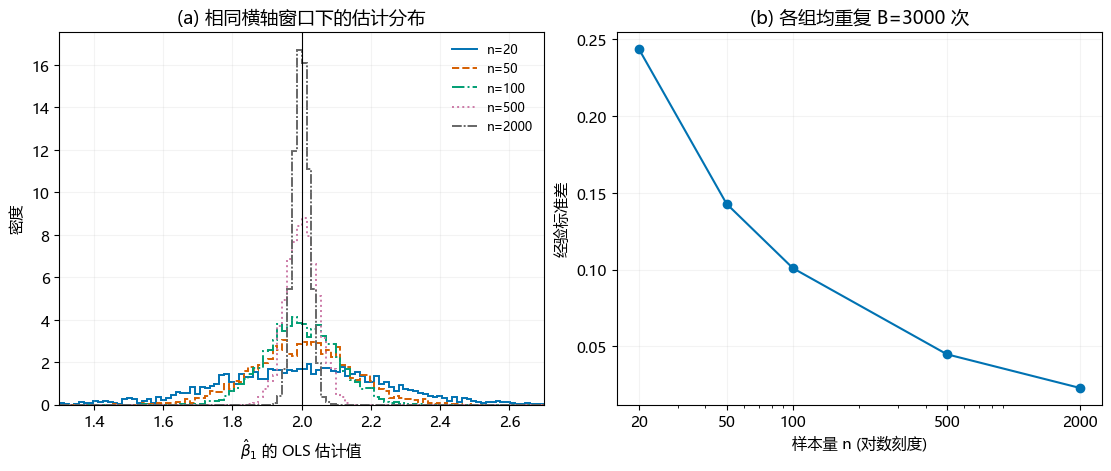

In [10]:
#| label: fig-mc-nb-ols-consistency
#| fig-cap: "OLS 一致性：不同样本量下的估计分布与经验标准差。"
# 一致性：共享显示窗口，密度以全部 B 次结果为分母，不重新归一化截尾样本。
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), layout='constrained')
edges = np.linspace(1.3, 2.7, 101)
for index, sample_size in enumerate(sample_sizes):
    estimates = ols_results[sample_size]
    counts, edges = np.histogram(estimates, bins=edges)
    axes[0].stairs(counts / len(estimates) / np.diff(edges), edges,
                   label=f'n={sample_size}', color=colors[index],
                   linestyle=line_styles[index], linewidth=1.4)
axes[0].axvline(2, color='black', linewidth=.8)
axes[0].set(xlabel=r'$\hat{\beta}_{1}$ 的 OLS 估计值', ylabel='密度', xlim=(1.3, 2.7),
            title='(a) 相同横轴窗口下的估计分布')
axes[0].legend(frameon=False, fontsize=9)
axes[1].plot(ols_summary['n'], ols_summary['empirical_sd'],
             marker='o', color=colors[0], label='经验标准差')
axes[1].set(xscale='log', xlabel='样本量 n (对数刻度)', ylabel='经验标准差',
            title='(b) 各组均重复 B=3000 次')
axes[1].set_xticks(sample_sizes, [str(value) for value in sample_sizes])
for axis in axes:
    axis.grid(alpha=.15)
plt.show()

In [11]:
display(ols_summary)

,n,mean_beta_hat,bias,empirical_sd
0,20,2.003953,0.003953,0.243743
1,50,2.001501,0.001501,0.142871
2,100,1.997104,-0.002896,0.100925
3,500,2.000313,0.000313,0.044825
4,2000,1.999967,-0.000033,0.022945


### IV：内生性与弱工具变量 {.unnumbered}

本例生成 $Y=\beta X+\gamma W+u$ 和 $X=\pi Z+\delta u+v$。独立标准正态变量 $Z,W,u,v$ 用于生成样本，$\delta$ 控制内生性，$\pi$ 控制工具变量与解释变量的相关性。每个样本同时计算 OLS 和 IV，结构参数真值均为 1。

#### 改变内生性 {.unnumbered}

固定 $n=500$、$B=1200$ 和 $\pi=1$，改变 $\delta$。下面先定义生成与估计函数，再比较两种估计均值。

In [12]:
def iv_mc(
    n=500,
    B=1200,
    beta=1.0,
    gamma=1.0,
    pi=1.0,
    delta=0.5,
    seed=SEED
):
    rng = np.random.default_rng(seed)
    ols_hat = np.empty(B)
    iv_hat = np.empty(B)

    for b in range(B):
        z = rng.normal(0, 1, n)
        w = rng.normal(0, 1, n)
        u = rng.normal(0, 1, n)
        v = rng.normal(0, 1, n)

        x = pi * z + delta * u + v
        y = beta * x + gamma * w + u

        X_ols = sm.add_constant(np.column_stack([x, w]))
        ols = sm.OLS(y, X_ols).fit()
        ols_hat[b] = ols.params[1]

        # IV2SLS: regressors = [const, x, w], instruments = [const, z, w]
        X_iv = sm.add_constant(np.column_stack([x, w]))
        Z_iv = sm.add_constant(np.column_stack([z, w]))
        iv = IV2SLS(y, X_iv, instrument=Z_iv).fit()
        iv_hat[b] = iv.params[1]

    return pd.DataFrame({"OLS": ols_hat, "IV": iv_hat})

In [13]:
delta_grid = [0.0, 0.2, 0.5, 0.8]
endogeneity_results = {}

for d in delta_grid:
    endogeneity_results[d] = iv_mc(
        n=500, B=1200, pi=1.0, delta=d, seed=SEED + int(d * 1000)
    )

summary_b1 = []
for d, df in endogeneity_results.items():
    for method in ["OLS", "IV"]:
        vals = df[method].to_numpy()
        summary_b1.append({
            "delta": d,
            "method": method,
            "mean": vals.mean(),
            "bias": vals.mean() - 1.0,
            "sd": vals.std(ddof=1),
            "rmse": np.sqrt(np.mean((vals - 1.0)**2)),
        })
pd.DataFrame(summary_b1)

,delta,method,mean,bias,sd,rmse
0,0.0,OLS,0.999194,-0.000806,0.031887,0.031884
1,0.0,IV,0.999176,-0.000824,0.045696,0.045684
2,0.2,OLS,1.098756,0.098756,0.030988,0.103500
3,0.2,IV,1.001215,0.001215,0.044697,0.044695
4,0.5,OLS,1.222924,0.222924,0.027821,0.224652
5,0.5,IV,0.998593,-0.001407,0.044248,0.044251
6,0.8,OLS,1.302554,0.302554,0.023513,0.303465
7,0.8,IV,0.997258,-0.002742,0.044214,0.044281


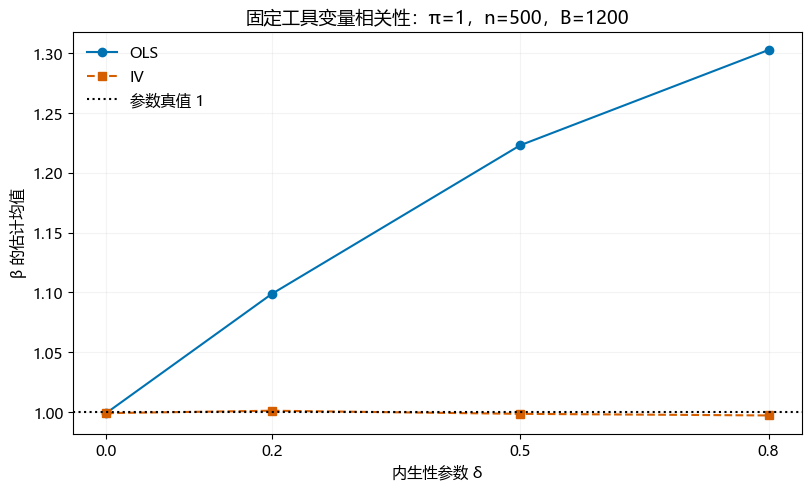

In [14]:
#| label: fig-mc-nb-iv-endogeneity
#| fig-cap: "固定工具变量相关性，比较内生性变化下的 OLS 与 IV 均值。"
# 内生性：比较同样本 OLS/IV 的估计均值，不添加未经解释的总体置信区间。
fig, axis = plt.subplots(figsize=(8, 4.8), layout='constrained')
for method, color, marker, style in [('OLS', colors[0], 'o', '-'),
                                      ('IV', colors[1], 's', '--')]:
    means = [endogeneity_results[value][method].mean() for value in delta_grid]
    axis.plot(delta_grid, means, color=color, marker=marker,
               linestyle=style, label=method)
axis.axhline(1, color='black', linestyle=':', label='参数真值 1')
axis.set(xlabel='内生性参数 δ', ylabel='β 的估计均值',
         title='固定工具变量相关性：π=1，n=500，B=1200')
axis.set_xticks(delta_grid)
axis.legend(frameon=False)
axis.grid(alpha=.15)
plt.show()

#### 减弱工具变量相关性 {.unnumbered}

固定内生性参数，依次降低 $\pi$，其余设置不变。两幅 ECDF 都以全部 1200 次估计为分母，左图保留极端估计，右图只放大真值附近，不重新归一化。

In [15]:
pi_grid = [1.0, 0.5, 0.2, 0.05]
weak_results = {}

for pival in pi_grid:
    weak_results[pival] = iv_mc(
        n=500, B=1200, pi=pival, delta=0.5,
        seed=SEED + int(pival * 10000)
    )

summary_b2 = []
for pival, df in weak_results.items():
    vals = df["IV"].to_numpy()
    summary_b2.append({
        "pi": pival,
        "mean_iv": vals.mean(),
        "bias_iv": vals.mean() - 1.0,
        "sd_iv": vals.std(ddof=1),
        "rmse_iv": np.sqrt(np.mean((vals - 1.0)**2)),
        "q01": np.quantile(vals, 0.01),
        "q99": np.quantile(vals, 0.99),
    })

pd.DataFrame(summary_b2)

,pi,mean_iv,bias_iv,sd_iv,rmse_iv,q01,q99
0,1.00,0.998715,-0.001285,0.045591,0.045591,0.886583,1.100663
1,0.50,0.994641,-0.005359,0.092376,0.092493,0.743024,1.187771
2,0.20,0.959567,-0.040433,0.282594,0.285355,0.133405,1.475303
3,0.05,2.122997,1.122997,27.981702,27.992576,-13.636707,23.415511


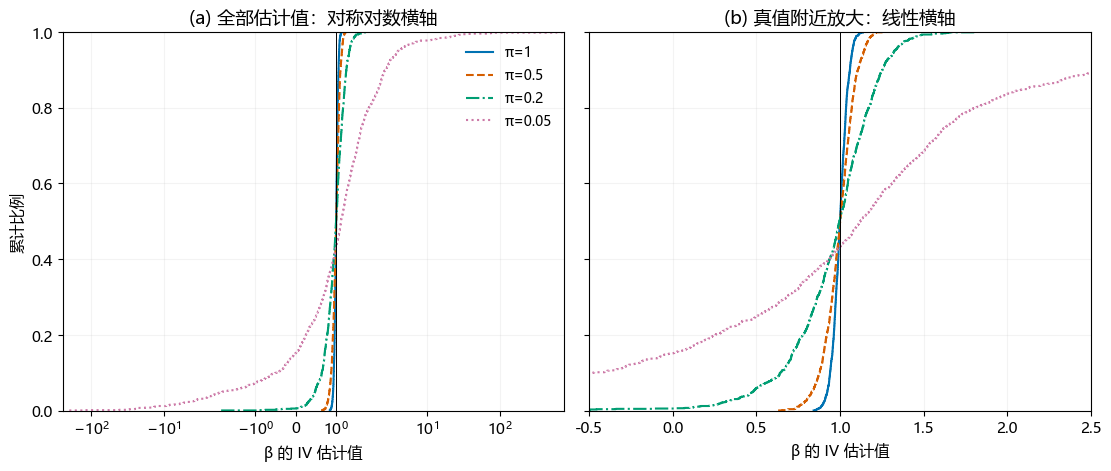

In [16]:
#| label: fig-mc-nb-iv-weak
#| fig-cap: "弱工具变量的完整经验分布及局部放大。"
# 弱工具变量：经验分布的分母始终为全部 1200 次，左图保留全部极端值。
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True, layout='constrained')
for index, instrument_strength in enumerate(pi_grid):
    estimates = np.sort(weak_results[instrument_strength]['IV'].to_numpy())
    probabilities = np.arange(1, len(estimates) + 1) / len(estimates)
    for axis in axes:
        axis.step(estimates, probabilities, where='post', color=colors[index],
                   linestyle=line_styles[index], linewidth=1.5,
                   label=f'π={instrument_strength:g}')
for axis in axes:
    axis.axvline(1, color='black', linewidth=.7)
    axis.set(xlabel='β 的 IV 估计值', ylim=(0, 1))
    axis.grid(alpha=.15)
axes[0].set_xscale('symlog', linthresh=2)
axes[0].set(title='(a) 全部估计值：对称对数横轴', ylabel='累计比例')
axes[1].set(title='(b) 真值附近放大：线性横轴', xlim=(-.5, 2.5))
axes[0].legend(frameon=False, fontsize=10)
plt.show()

工具较弱时，IV 估计更容易出现远离真值的结果。应结合完整分布和分位数阅读，不能只用一个平均值概括。

::: {.callout-note collapse="true" title="案例一结果核对与导出"}

In [17]:
from pathlib import Path
import os
export_dir = OUTPUT / 'case1'
export_dir.mkdir(parents=True, exist_ok=True)
arrays = {'unbiased': bhat_100}
arrays.update({f'consistency_{sample_size}': values for sample_size, values in ols_results.items()})
arrays.update({f'endogeneity_{value:g}': results.to_numpy() for value, results in endogeneity_results.items()})
arrays.update({f'weak_{value:g}': results.to_numpy() for value, results in weak_results.items()})
np.savez_compressed(export_dir / 'estimates.npz', **arrays)
ols_summary.to_csv(export_dir / 'ols-consistency.csv', index=False, encoding='utf-8-sig')
pd.DataFrame(summary_b1).to_csv(export_dir / 'iv-endogeneity.csv', index=False, encoding='utf-8-sig')
pd.DataFrame(summary_b2).to_csv(export_dir / 'iv-weak.csv', index=False, encoding='utf-8-sig')
display(ols_summary)
display(pd.DataFrame(summary_b1))
display(pd.DataFrame(summary_b2))

,n,mean_beta_hat,bias,empirical_sd
0,20,2.003953,0.003953,0.243743
1,50,2.001501,0.001501,0.142871
2,100,1.997104,-0.002896,0.100925
3,500,2.000313,0.000313,0.044825
4,2000,1.999967,-0.000033,0.022945


,delta,method,mean,bias,sd,rmse
0,0.0,OLS,0.999194,-0.000806,0.031887,0.031884
1,0.0,IV,0.999176,-0.000824,0.045696,0.045684
2,0.2,OLS,1.098756,0.098756,0.030988,0.103500
3,0.2,IV,1.001215,0.001215,0.044697,0.044695
4,0.5,OLS,1.222924,0.222924,0.027821,0.224652
5,0.5,IV,0.998593,-0.001407,0.044248,0.044251
6,0.8,OLS,1.302554,0.302554,0.023513,0.303465
7,0.8,IV,0.997258,-0.002742,0.044214,0.044281


,pi,mean_iv,bias_iv,sd_iv,rmse_iv,q01,q99
0,1.00,0.998715,-0.001285,0.045591,0.045591,0.886583,1.100663
1,0.50,0.994641,-0.005359,0.092376,0.092493,0.743024,1.187771
2,0.20,0.959567,-0.040433,0.282594,0.285355,0.133405,1.475303
3,0.05,2.122997,1.122997,27.981702,27.992576,-13.636707,23.415511


In [18]:
case_results['case1'] = {'mean': float(bhat_100.mean()), 'bias': float(bhat_100.mean()-2), 'arrays': len(arrays)}

:::

## 案例二：项目估值 {.unnumbered #sec-mc-nb-valuation}

[返回正文：案例二](../../lectures/monte-carlo.qmd#sec-mc-valuation)。

企业选择价格后，由年度需求冲击生成市场份额，再沿销量、收入和现金流关系计算项目 NPV。价格是决策变量，需求冲击和贴现率是不确定性因素，市场份额及 NPV 是模型计算结果。

本例期限为 10 年，年度潜在市场规模为 100 万件，初始投资 3500 万元，年度固定支出 600 万元，现金流转化比例为 0.28。需求冲击标准差为 0.55。贴现率设为 $r=0.05+0.07X_{r}$，其中 $X_{r}\sim Beta(3,4)$。每个情景使用一个贴现率，需求冲击按年独立抽取。金额计算使用元，NPV 表和图使用百万元。

实际应用中，市场规模可结合行业资料与市场调研估算，现金流比例与固定支出需参考财务记录，价格敏感性则需要历史销售或试销资料支持。本页参数为教学设定，不是这些资料的实证估计。

### 经营关系与参数 {.unnumbered}

现金流采用 $FCF_{t}=mpQ_{0}s_{t}-F$，NPV 为未来十年各年末现金流的现值之和减去初始投资。代码中的 `p_ref` 对应正文的市场参考价格 $\bar p=100$，`simulate_project` 内部独立初始化发生器，比较价格时保留共同随机输入。

In [19]:
SEED = 20261001

# 教学参数
T = 10
Q0 = 1_000_000
p_ref = 100.0
alpha = -0.4
beta_price = 2.2
sigma_eps = 0.55

m = 0.28
F = 6_000_000
I0 = 35_000_000

a_r = 3.0
b_r = 4.0
r_min = 0.05
r_max = 0.12

B = 20_000

In [20]:
def logistic(x):
    return 1 / (1 + np.exp(-x))

def simulate_project(
    p,
    B=B,
    seed=SEED,
    Q0=Q0,
    alpha=alpha,
    beta_price=beta_price,
    p_ref=p_ref,
    sigma_eps=sigma_eps,
    m=m,
    F=F,
    I0=I0,
    T=T,
    a_r=a_r,
    b_r=b_r,
    r_min=r_min,
    r_max=r_max,
):
    rng = np.random.default_rng(seed)
    eps = rng.normal(0, sigma_eps, size=(B, T))
    share = logistic(
        alpha - beta_price * np.log(p / p_ref) + eps
    )
    quantity = share * Q0
    sales = p * quantity
    fcf = m * sales - F

    x_r = rng.beta(a_r, b_r, size=B)
    discount_rate = r_min + (r_max - r_min) * x_r

    years = np.arange(1, T + 1)
    df = (1 + discount_rate[:, None]) ** years
    npv = -I0 + np.sum(fcf / df, axis=1)

    # 贴现加权份额使用各情景自身的贴现率，不改变原 NPV 计算。
    discount_weight = (1 + discount_rate[:, None]) ** (-years)
    weighted_share = np.sum(share * discount_weight, axis=1) / discount_weight.sum(axis=1)

    return {
        "weighted_share": weighted_share,
        "npv": npv,
        "share": share,
        "avg_share": share.mean(axis=1),
        "quantity": quantity,
        "sales": sales,
        "fcf": fcf,
        "discount_rate": discount_rate,
    }

def annuity_factor(r, T=T):
    return (1 - (1 + r) ** (-T)) / r

def required_share_for_npv_zero(p, r):
    af = annuity_factor(r)
    annual_fcf_required = I0 / af
    annual_sales_contribution_required = annual_fcf_required + F
    return annual_sales_contribution_required / (m * p * Q0)

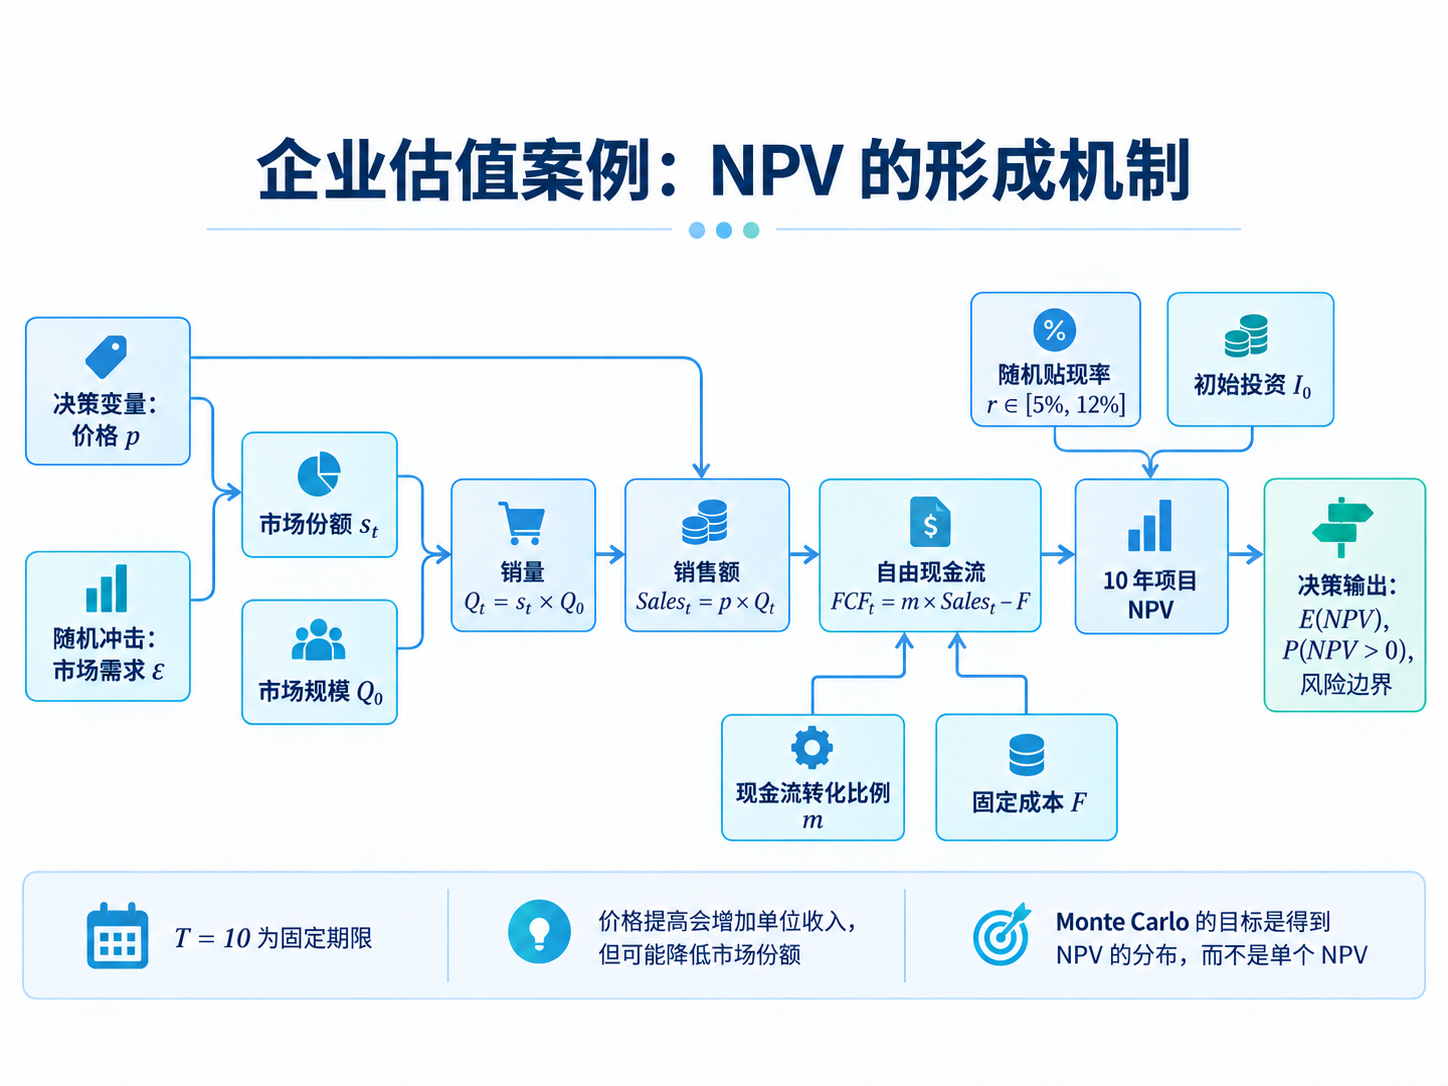

In [21]:
#| label: fig-mc-nb-valuation-mechanism
#| fig-cap: "经营关系：现金流转化比例与固定支出作用于自由现金流。"
display(Image(filename=str(ROOT / 'figs/raw/mc-valuation-fig01-mechanism-corrected-20261017-225145.png')))

### 从一个情景到 NPV 分布 {.unnumbered}

在价格 80 元下生成 20000 个十年经营情景。核心数组每行对应一个情景，每列对应一年。沿年份折现汇总现金流后，每个情景得到一个 NPV。均值说明预期价值，正 NPV 比例与 5% 分位数分别反映满足投资标准的概率及下行损失。

In [22]:
base_p = 80.0
base = simulate_project(base_p)

summary = pd.Series({
    "Price": base_p,
    "Mean NPV (million)": base["npv"].mean() / 1e6,
    "Median NPV (million)": np.median(base["npv"]) / 1e6,
    "P(NPV > 0)": np.mean(base["npv"] > 0),
    "NPV 5% quantile (million)": np.quantile(base["npv"], 0.05) / 1e6,
    "NPV 95% quantile (million)": np.quantile(base["npv"], 0.95) / 1e6,
    "Mean market share": base["share"].mean(),
    "Mean discounted market share": base["weighted_share"].mean(),
    "Mean discount rate": base["discount_rate"].mean(),
})
summary

Price                           80.000000
Mean NPV (million)               3.188084
Median NPV (million)             3.122746
P(NPV > 0)                       0.683650
NPV 5% quantile (million)       -7.493066
NPV 95% quantile (million)      14.108453
Mean market share                0.521222
Mean discounted market share     0.521400
Mean discount rate               0.080055
dtype: float64

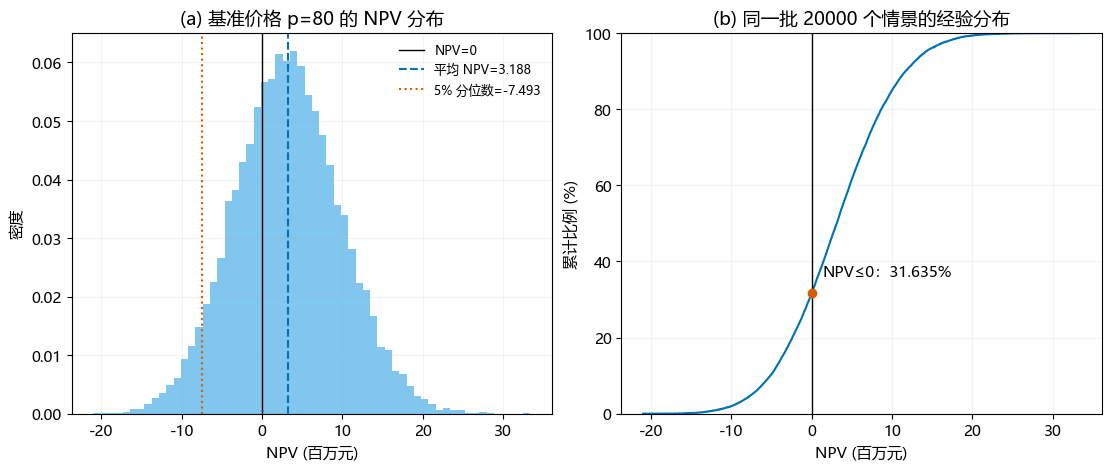

In [23]:
#| label: fig-mc-nb-valuation-npv
#| fig-cap: "价格 80 元下的 NPV 分布与经验累积分布。"
# BASELINE_FIGURE
plt.rcParams.update({'font.family': 'Microsoft YaHei', 'font.size': 11,
                     'axes.unicode_minus': False})
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), layout='constrained')
values = base['npv'] / 1e6
axes[0].hist(values, bins=60, density=True, color='#56B4E9', alpha=.75)
axes[0].axvline(0, color='black', linewidth=1, label='NPV=0')
axes[0].axvline(values.mean(), color='#0072B2', linestyle='--',
                label=f'平均 NPV={values.mean():.3f}')
axes[0].axvline(np.quantile(values, .05), color='#D55E00', linestyle=':',
                label=f'5% 分位数={np.quantile(values, .05):.3f}')
axes[0].set(title='(a) 基准价格 p=80 的 NPV 分布', xlabel='NPV (百万元)', ylabel='密度')
axes[0].legend(frameon=False, fontsize=9)
sorted_values = np.sort(values)
probabilities = np.arange(1, B + 1) / B
axes[1].step(sorted_values, probabilities * 100, where='post', color='#0072B2')
nonpositive = np.mean(values <= 0) * 100
axes[1].axvline(0, color='black', linewidth=1)
axes[1].scatter([0], [nonpositive], color='#D55E00', zorder=3)
axes[1].annotate(f'NPV≤0：{nonpositive:.3f}%', xy=(0, nonpositive),
                 xytext=(8, 12), textcoords='offset points')
axes[1].set(title='(b) 同一批 20000 个情景的经验分布',
            xlabel='NPV (百万元)', ylabel='累计比例 (%)', ylim=(0, 100))
for axis in axes:
    axis.grid(alpha=.15)
plt.show()

### 从 NPV 分布进入价格决策 {.unnumbered}

候选价格从 55 到 160 元，间隔 5 元。每个价格使用同样的模拟次数和随机输入，以便比较价格改变后的经营结果。结果缓存只避免重复计算，不改变抽样顺序或算法。

In [24]:
price_grid = np.arange(55, 161, 5)

valuation_cache = {float(price): simulate_project(price) for price in price_grid}
rows = []
for p in price_grid:
    result = valuation_cache[float(p)]
    rows.append({
        "price": p,
        "mean_npv_million": result["npv"].mean() / 1e6,
        "median_npv_million": np.median(result["npv"]) / 1e6,
        "prob_positive": np.mean(result["npv"] > 0),
        "npv_5pct_million": np.quantile(result["npv"], 0.05) / 1e6,
        "mean_share": result["share"].mean(),
    })

price_results = pd.DataFrame(rows)
price_results

,price,mean_npv_million,median_npv_million,prob_positive,npv_5pct_million,mean_share
0,55,-2.619689,-2.620367,0.25885,-9.288763,0.702153
1,60,-0.411728,-0.424316,0.46425,-8.002956,0.663165
2,65,1.201970,1.180067,0.59120,-7.269648,0.625320
3,70,2.294102,2.255193,0.65585,-6.984696,0.588925
4,75,2.934453,2.886355,0.68225,-7.074938,0.554185
5,80,3.188084,3.122746,0.68365,-7.493066,0.521222
6,85,3.114320,3.024545,0.66845,-8.159387,0.490092
7,90,2.766341,2.635134,0.64180,-8.994470,0.460803
8,95,2.191171,2.014173,0.60790,-9.976331,0.433329
9,100,1.429937,1.243946,0.56340,-11.085646,0.407615


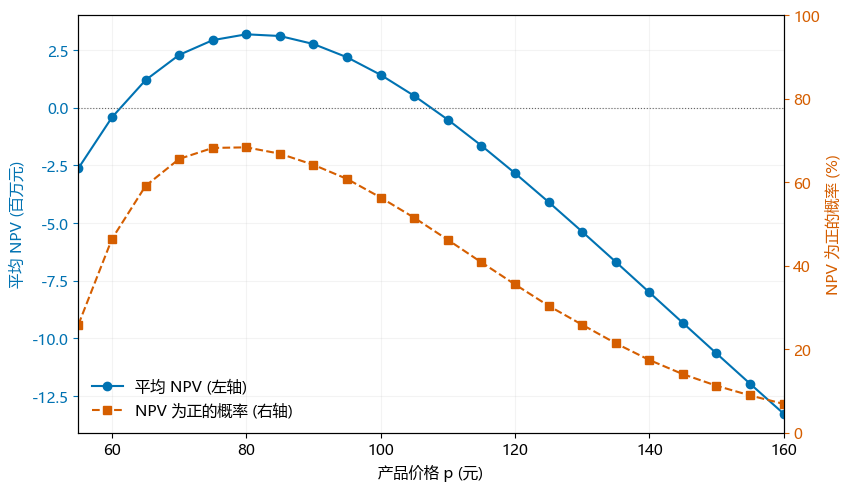

In [25]:
#| label: fig-mc-nb-valuation-prices
#| fig-cap: "候选价格下的平均 NPV 与正 NPV 概率。左轴为平均 NPV (百万元)，右轴为正 NPV 概率 (%)，虚线水平线表示左轴 NPV 为零。两条曲线的交点没有经济含义。"
fig, value_axis = plt.subplots(figsize=(8.4, 4.8), layout='constrained')
probability_axis = value_axis.twinx()
value_line, = value_axis.plot(price_results['price'], price_results['mean_npv_million'],
                            marker='o', color='#0072B2', label='平均 NPV (左轴)')
probability_line, = probability_axis.plot(price_results['price'], price_results['prob_positive'] * 100,
                                        marker='s', linestyle='--', color='#D55E00',
                                        label='NPV 为正的概率 (右轴)')
value_axis.axhline(0, color='#666666', linewidth=.8, linestyle=':')
value_axis.set(xlabel='产品价格 p (元)', ylabel='平均 NPV (百万元)',
               xlim=(price_grid.min(), price_grid.max()))
probability_axis.set(ylabel='NPV 为正的概率 (%)', ylim=(0, 100))
value_axis.tick_params(axis='y', colors='#0072B2')
probability_axis.tick_params(axis='y', colors='#D55E00')
value_axis.yaxis.label.set_color('#0072B2')
probability_axis.yaxis.label.set_color('#D55E00')
value_axis.grid(alpha=.15)
value_axis.legend(handles=[value_line, probability_line], loc='lower left', frameon=False)
plt.show()

本组网格中，80 元的平均 NPV 和正 NPV 概率最高，70 元的 5% 分位数最高。三项指标未必指向同一方案。这里没有另外指定企业风险约束，不给出唯一最优价格。

### NPV = 0 的决策边界 {.unnumbered}

固定年度份额时，临界份额由价格与贴现率决定。年度份额随冲击变化时，需要按各年的贴现系数计算加权平均，再与同一情景贴现率下的门槛比较。简单平均份额不能保证与逐年 NPV 对应。

下图边界带来自贴现率上下限，不是置信区间。左图每价选 250 个情景显示，右图显示基准价格的全部 20000 个情景。

In [26]:
p_boundary = np.linspace(55, 160, 400)

s_low_r = required_share_for_npv_zero(p_boundary, r_min)
s_high_r = required_share_for_npv_zero(p_boundary, r_max)

# 贴现率均值对应的中心边界
mean_r = r_min + (r_max - r_min) * (a_r / (a_r + b_r))
s_mean_r = required_share_for_npv_zero(p_boundary, mean_r)

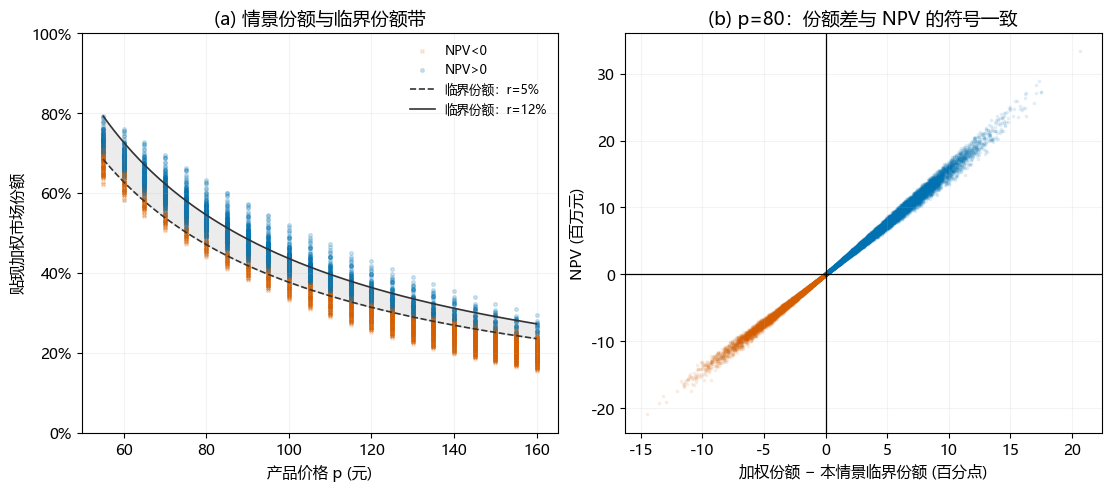

In [27]:
#| label: fig-mc-nb-valuation-boundary
#| fig-cap: "贴现加权份额与 NPV=0 门槛的对应关系。"
# WEIGHTED_BOUNDARY_FIGURE
from matplotlib.ticker import PercentFormatter
display_rng = np.random.default_rng(SEED + 98765)
display_indices = display_rng.choice(B, size=250, replace=False)
sample_rows = []
for price in price_grid:
    scenario = simulate_project(price, B=B, seed=SEED)
    sample_rows.append(pd.DataFrame({
        'price': price, 'weighted_share': scenario['weighted_share'][display_indices],
        'discount_rate': scenario['discount_rate'][display_indices],
        'npv': scenario['npv'][display_indices],
    }))
scatter_df = pd.concat(sample_rows, ignore_index=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), layout='constrained')
for positive, color, marker, label in [(False, '#D55E00', 'x', 'NPV<0'),
                                       (True, '#0072B2', 'o', 'NPV>0')]:
    selected = scatter_df['npv'] > 0 if positive else scatter_df['npv'] < 0
    axes[0].scatter(scatter_df.loc[selected, 'price'], scatter_df.loc[selected, 'weighted_share'],
                     color=color, marker=marker, s=7, alpha=.18, label=label)
axes[0].fill_between(p_boundary, s_low_r, s_high_r, color='.5', alpha=.15)
axes[0].plot(p_boundary, s_low_r, color='.2', linestyle='--', linewidth=1.2, label='临界份额：r=5%')
axes[0].plot(p_boundary, s_high_r, color='.2', linestyle='-', linewidth=1.2, label='临界份额：r=12%')
axes[0].set(xlabel='产品价格 p (元)', ylabel='贴现加权市场份额', ylim=(0, 1),
            title='(a) 情景份额与临界份额带')
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].legend(frameon=False, fontsize=9, loc='upper right')
critical_base = required_share_for_npv_zero(base_p, base['discount_rate'])
share_gap = base['weighted_share'] - critical_base
for positive, color in [(False, '#D55E00'), (True, '#0072B2')]:
    selected = base['npv'] > 0 if positive else base['npv'] < 0
    axes[1].scatter(share_gap[selected] * 100, base['npv'][selected] / 1e6,
                     s=3, alpha=.08, color=color)
axes[1].axvline(0, color='black', linewidth=.9)
axes[1].axhline(0, color='black', linewidth=.9)
axes[1].set(title='(b) p=80：份额差与 NPV 的符号一致',
            xlabel='加权份额 − 本情景临界份额 (百分点)', ylabel='NPV (百万元)')
for axis in axes:
    axis.grid(alpha=.15)
plt.show()

::: {.callout-note collapse="true" title="案例二压力测试、边界核验与稳定性"}

压力测试改变市场规模、固定支出或贴现率分布。下面同时核验 NPV 两种计算方式、同样算术平均而时序不同的反例，以及种子变化时的价格比较结果。

In [28]:
def scenario_summary(name, **kwargs):
    result = simulate_project(base_p, **kwargs)
    return {
        "scenario": name,
        "mean_npv_million": result["npv"].mean() / 1e6,
        "prob_positive": np.mean(result["npv"] > 0),
        "npv_5pct_million": np.quantile(result["npv"], 0.05) / 1e6,
    }

stress_results = pd.DataFrame([
    scenario_summary("Baseline"),
    scenario_summary("Market size -15%", Q0=Q0 * 0.85),
    scenario_summary("Fixed cost +20%", F=F * 1.20),
    scenario_summary(
        "Higher discount rates",
        r_min=0.08,
        r_max=0.12,
        a_r=3.0,
        b_r=2.0,
    ),
])

stress_results

,scenario,mean_npv_million,prob_positive,npv_5pct_million
0,Baseline,3.188084,0.68365,-7.493066
1,Market size -15%,-8.591847,0.06120,-17.537460
2,Fixed cost +20%,-4.880873,0.22285,-15.381794
3,Higher discount rates,-0.665372,0.45135,-10.112402


In [29]:
diagnostics = pd.Series({
    "share_min": base["share"].min(),
    "share_max": base["share"].max(),
    "discount_rate_min": base["discount_rate"].min(),
    "discount_rate_max": base["discount_rate"].max(),
    "has_positive_npv": bool(np.any(base["npv"] > 0)),
    "has_negative_npv": bool(np.any(base["npv"] < 0)),
})
diagnostics

share_min            0.092589
share_max            0.921179
discount_rate_min    0.051174
discount_rate_max    0.117311
has_positive_npv         True
has_negative_npv         True
dtype: object

In [30]:
"""价格决策指标与贴现加权市场份额的可执行核验。"""
from pathlib import Path
import json
import os

export_dir = OUTPUT / 'valuation'
export_dir.mkdir(parents=True, exist_ok=True)
years = np.arange(1, T + 1)
valuation_scenarios = {}
decision_rows = []
validation_rows = []
for price in price_grid:
    scenario = valuation_cache[float(price)]
    discount = (1 + scenario['discount_rate'][:, None]) ** (-years)
    annuity = discount.sum(axis=1)
    weighted_share = (scenario['share'] * discount).sum(axis=1) / annuity
    critical_share = (F + I0 / annuity) / (m * price * Q0)
    reconstructed_npv = -I0 + (m * price * Q0 * weighted_share - F) * annuity
    gap_npv = m * price * Q0 * annuity * (weighted_share - critical_share)
    original_npv = scenario['npv']
    direct_positive = original_npv > 0
    weighted_positive = weighted_share > critical_share
    arithmetic_positive = scenario['avg_share'] > critical_share
    identity_error = np.abs(original_npv - reconstructed_npv).max()
    assert np.allclose(original_npv, reconstructed_npv, rtol=1e-12, atol=1e-6)
    assert np.allclose(original_npv, gap_npv, rtol=1e-12, atol=1e-6)
    assert np.array_equal(direct_positive, weighted_positive)
    assert np.array_equal(annuity > 0, np.ones(B, dtype=bool))
    assert np.allclose(annuity, annuity_factor(scenario['discount_rate']), rtol=1e-13, atol=1e-13)
    assert np.allclose(critical_share, required_share_for_npv_zero(price, scenario['discount_rate']))
    low = required_share_for_npv_zero(price, r_min)
    high = required_share_for_npv_zero(price, r_max)
    assert low < high
    assert np.all(direct_positive[weighted_share > high])
    assert not np.any(direct_positive[weighted_share < low])
    valuation_scenarios[price] = {
        'npv': original_npv, 'weighted_share': weighted_share,
        'avg_share': scenario['avg_share'], 'critical_share': critical_share,
        'discount_rate': scenario['discount_rate'],
    }
    decision_rows.append({
        'price': price, 'mean_npv_million': original_npv.mean() / 1e6,
        'median_npv_million': np.median(original_npv) / 1e6,
        'prob_positive': direct_positive.mean(),
        'npv_5pct_million': np.quantile(original_npv, .05) / 1e6,
        'mean_mcse_million': original_npv.std(ddof=1) / np.sqrt(B) / 1e6,
        'mean_share': scenario['share'].mean(),
        'zero_npv_count': int((original_npv == 0).sum()),
    })
    validation_rows.append({
        'price': price, 'B': B, 'max_identity_error': identity_error,
        'weighted_sign_mismatches': int((direct_positive != weighted_positive).sum()),
        'arithmetic_sign_mismatches': int((direct_positive != arithmetic_positive).sum()),
    })

decision_results = pd.DataFrame(decision_rows)
weighted_checks = pd.DataFrame(validation_rows)
decision_results.to_csv(export_dir / 'price-results.csv', index=False, encoding='utf-8-sig')
weighted_checks.to_csv(export_dir / 'weighted-checks.csv', index=False, encoding='utf-8-sig')
summary.rename('value').to_csv(export_dir / 'baseline-summary.csv', encoding='utf-8-sig')
stress_results.to_csv(export_dir / 'stress-results.csv', index=False, encoding='utf-8-sig')
np.savez_compressed(export_dir / 'scenarios.npz', prices=price_grid,
    npv=np.stack([valuation_scenarios[price]['npv'] for price in price_grid]),
    weighted_share=np.stack([valuation_scenarios[price]['weighted_share'] for price in price_grid]),
    arithmetic_share=np.stack([valuation_scenarios[price]['avg_share'] for price in price_grid]),
    critical_share=np.stack([valuation_scenarios[price]['critical_share'] for price in price_grid]),
    discount_rate=np.stack([valuation_scenarios[price]['discount_rate'] for price in price_grid]))

# 构造简单平均完全相同、但较高份额出现时间不同的两条记录。
example_rate = .08
example_price = 80.
example_discount = (1 + example_rate) ** (-years)
examples = []
for name, shares in [('较高份额在前五年', np.r_[np.full(5, .8), np.full(5, .2)]),
                      ('较高份额在后五年', np.r_[np.full(5, .2), np.full(5, .8)])]:
    weighted = np.sum(shares * example_discount) / example_discount.sum()
    value = -I0 + np.sum((m * example_price * Q0 * shares - F) * example_discount)
    examples.append({'example': name, 'arithmetic_share': shares.mean(),
        'weighted_share': weighted, 'critical_share': required_share_for_npv_zero(example_price, example_rate),
        'npv_million': value / 1e6})
counterexample = pd.DataFrame(examples)
assert np.isclose(counterexample.arithmetic_share.iloc[0], counterexample.arithmetic_share.iloc[1])
assert counterexample.npv_million.iloc[0] > 0 and counterexample.npv_million.iloc[1] < 0
counterexample.to_csv(export_dir / 'same-average-counterexample.csv', index=False, encoding='utf-8-sig')

# 在门槛及两侧做确定性检查，舍入误差不作为 NPV=0 的经济偏差。
rates = np.linspace(r_min, r_max, 51)
annuity = np.sum((1 + rates[:, None]) ** (-years), axis=1)
required = (F + I0 / annuity) / (m * example_price * Q0)
zero_npv = -I0 + (m * example_price * Q0 * required - F) * annuity
assert np.max(np.abs(zero_npv)) < 1e-6
assert np.all(-I0 + (m * example_price * Q0 * (required + 1e-4) - F) * annuity > 0)
assert np.all(-I0 + (m * example_price * Q0 * (required - 1e-4) - F) * annuity < 0)
assert np.all(np.diff(required) > 0)
assert np.all(np.diff(required_share_for_npv_zero(price_grid, .08)) < 0)
assert required_share_for_npv_zero(30., .08) > 1

maxima = {}
for metric in ['mean_npv_million', 'prob_positive', 'npv_5pct_million']:
    row = decision_results.loc[decision_results[metric].idxmax()]
    maxima[metric] = {'price': float(row.price), 'value': float(row[metric])}
audit = {
    'price_count': len(price_grid), 'B': B, 'scenario_count': len(price_grid) * B,
    'weighted_sign_mismatches': int(weighted_checks.weighted_sign_mismatches.sum()),
    'arithmetic_sign_mismatches': int(weighted_checks.arithmetic_sign_mismatches.sum()),
    'max_identity_error': float(weighted_checks.max_identity_error.max()),
    'fixed_share_boundary_max_abs_npv': float(np.abs(zero_npv).max()),
    'grid_maxima': maxima, 'same_random_inputs_across_prices': bool(all(np.array_equal(
        valuation_scenarios[price_grid[0]]['discount_rate'], valuation_scenarios[price]['discount_rate']) for price in price_grid)),
}
(export_dir / 'weighted-audit.json').write_text(json.dumps(audit, ensure_ascii=False, indent=2), encoding='utf-8')
display(weighted_checks)
display(counterexample)
print(json.dumps(audit, ensure_ascii=False, indent=2))

,price,B,max_identity_error,weighted_sign_mismatches,arithmetic_sign_mismatches
0,55,20000,4.470348e-08,0,870
1,60,20000,4.470348e-08,0,1275
2,65,20000,4.470348e-08,0,1312
3,70,20000,4.470348e-08,0,1241
4,75,20000,4.470348e-08,0,1214
5,80,20000,4.470348e-08,0,1238
6,85,20000,5.215406e-08,0,1257
7,90,20000,5.960464e-08,0,1299
8,95,20000,5.215406e-08,0,1287
9,100,20000,4.470348e-08,0,1358


,example,arithmetic_share,weighted_share,critical_share,npv_million
0,较高份额在前五年,0.5,0.557019,0.500716,8.462699
1,较高份额在后五年,0.5,0.442981,0.500716,-8.677853


{
  "price_count": 22,
  "B": 20000,
  "scenario_count": 440000,
  "weighted_sign_mismatches": 0,
  "arithmetic_sign_mismatches": 24268,
  "max_identity_error": 5.960464477539063e-08,
  "fixed_share_boundary_max_abs_npv": 1.4901161193847656e-08,
  "grid_maxima": {
    "mean_npv_million": {
      "price": 80.0,
      "value": 3.1880844668561434
    },
    "prob_positive": {
      "price": 80.0,
      "value": 0.68365
    },
    "npv_5pct_million": {
      "price": 70.0,
      "value": -6.984696376603105
    }
  },
  "same_random_inputs_across_prices": true
}


In [31]:
"""相同模型下的种子敏感性与相邻价格的配对 Monte Carlo 误差。"""
stability_rows = []
for comparison_seed in [SEED, SEED + 1, SEED + 2]:
    for price in price_grid:
        scenario = simulate_project(price, B=B, seed=comparison_seed)
        stability_rows.append({
            'seed': comparison_seed, 'price': price,
            'mean_npv_million': scenario['npv'].mean() / 1e6,
            'prob_positive': np.mean(scenario['npv'] > 0),
            'npv_5pct_million': np.quantile(scenario['npv'], .05) / 1e6,
        })
seed_comparison = pd.DataFrame(stability_rows)
seed_comparison.to_csv(export_dir / 'seed-comparison.csv', index=False, encoding='utf-8-sig')
peak_rows = []
for comparison_seed, group in seed_comparison.groupby('seed'):
    for metric in ['mean_npv_million', 'prob_positive', 'npv_5pct_million']:
        peak = group.loc[group[metric].idxmax()]
        peak_rows.append({'seed': comparison_seed, 'metric': metric,
                          'price': peak.price, 'value': peak[metric]})
seed_peaks = pd.DataFrame(peak_rows)
seed_peaks.to_csv(export_dir / 'seed-peaks.csv', index=False, encoding='utf-8-sig')
baseline_probability_difference = ((valuation_scenarios[80]['npv'] > 0).astype(float)
                                   - (valuation_scenarios[75]['npv'] > 0).astype(float))
paired_probability_check = pd.Series({
    'price_80_minus_75_probability_difference': baseline_probability_difference.mean(),
    'paired_MC_standard_error': baseline_probability_difference.std(ddof=1) / np.sqrt(B),
})
paired_probability_check.to_csv(export_dir / 'paired-probability-check.csv', encoding='utf-8-sig')
display(seed_peaks)
display(paired_probability_check)
print('以上检查反映有限次模拟的数值波动，不构成需求关系或项目价值的现实不确定性区间。')

,seed,metric,price,value
0,20261001,mean_npv_million,80.0,3.188084
1,20261001,prob_positive,80.0,0.683650
2,20261001,npv_5pct_million,70.0,-6.984696
3,20261002,mean_npv_million,80.0,3.144136
4,20261002,prob_positive,80.0,0.677550
5,20261002,npv_5pct_million,70.0,-7.036581
6,20261003,mean_npv_million,80.0,3.122301
7,20261003,prob_positive,80.0,0.675700
8,20261003,npv_5pct_million,70.0,-7.035482


price_80_minus_75_probability_difference    0.001400
paired_MC_standard_error                    0.000686
dtype: float64

以上检查反映有限次模拟的数值波动，不构成需求关系或项目价值的现实不确定性区间。


In [32]:
case_results['valuation'] = audit

:::

## 案例三：用真实数据校准组合风险模型 {.unnumbered #sec-mc-nb-portfolio}

[返回正文：案例三](../../lectures/monte-carlo.qmd#sec-mc-portfolio)。

前两例预先设定了生成机制。本例根据五只股票的历史收益估计均值、波动和共同变化，再比较正态模拟、历史整行重抽样与多日区块抽样。它们使用相同的两组组合权重，重点是生成方式怎样影响损失分布，不把本例解释为实时风险预测。

### 数据、股票池与组合权重 {.unnumbered}

股票为招商银行、长江电力、万科 A、格力电器和比亚迪。共同有效日收益覆盖 2016-09-05 至 2026-09-30，共 2397 日。日收益由后复权价格计算。等权组合各占 20%，市值权重使用 2026-09-30 五只股票总市值的相对比例，比较方法时不改变权重。

下面只读取仓库处理后数据。价格文件保留原始日期和缺失位置，用于识别连续区块；收益文件只包含共同有效日。不能把删除缺失后的有效日序列直接当作没有间断的交易日序列。接口与口径资料见[数据说明](../../data/monte-carlo/README.md)。

In [33]:
portfolio_data = ROOT / 'data/monte-carlo'
required_inputs = ['returns.csv', 'adjusted_prices.csv', 'portfolio-results/portfolio_weights.csv', 'stock_pool.csv']
missing_inputs = [name for name in required_inputs if not (portfolio_data / name).is_file()]
if missing_inputs:
    raise FileNotFoundError('缺少仓库冻结文件：' + ', '.join(missing_inputs))
portfolio_returns = pd.read_csv(portfolio_data / 'returns.csv', index_col=0, parse_dates=True, encoding='utf-8-sig')
portfolio_prices = pd.read_csv(portfolio_data / 'adjusted_prices.csv', index_col=0, parse_dates=True, encoding='utf-8-sig')
portfolio_weight_table = pd.read_csv(portfolio_data / 'portfolio-results/portfolio_weights.csv', dtype={'code': str}, encoding='utf-8-sig').set_index('code').loc[portfolio_returns.columns]
portfolio_weights = portfolio_weight_table[['equal_weight', 'value_weight']].to_numpy()
portfolio_names = ['等权组合', '市值权重组合']
stock_names = portfolio_weight_table['name'].tolist()
assert portfolio_returns.index.is_unique and portfolio_prices.index.is_unique
assert portfolio_returns.index.is_monotonic_increasing and portfolio_prices.index.is_monotonic_increasing
assert portfolio_returns.index.isin(portfolio_prices.index).all()
assert np.isfinite(portfolio_returns.to_numpy()).all()
assert (portfolio_returns.to_numpy() > -1).all()
assert np.isfinite(portfolio_weights).all() and (portfolio_weights >= 0).all()
assert np.allclose(portfolio_weights.sum(axis=0), 1)
display(pd.Series({'共同有效日': len(portfolio_returns), '原日期索引长度': len(portfolio_prices),
                   '开始': str(portfolio_returns.index.min().date()), '结束': str(portfolio_returns.index.max().date())}))
display(portfolio_weight_table[['name', 'sector', 'equal_weight', 'value_weight', 'reference_date']])

共同有效日            2397
原日期索引长度          2611
开始         2016-09-05
结束         2026-09-30
dtype: object

,name,sector,equal_weight,value_weight,reference_date
600036,招商银行,银行,0.2,0.376514,2026-09-30
600900,长江电力,电力,0.2,0.252677,2026-09-30
000002,万科 A,房地产,0.2,0.018390,2026-09-30
000651,格力电器,家电,0.2,0.077585,2026-09-30
002594,比亚迪,汽车,0.2,0.274833,2026-09-30


### 用历史数据设定联合分布 {.unnumbered}

每行是同一天五只股票的收益。按列计算均值得到五维均值向量，样本协方差矩阵的对角线表示各股票收益方差，非对角线表示共同变化。下面显示完整估计矩阵，并画相关系数图，便于按股票名称查阅。

招商银行    0.000490
长江电力    0.000388
万科 A   -0.000271
格力电器    0.000397
比亚迪     0.000921
Name: 平均日收益率, dtype: float64

,招商银行,长江电力,万科 A,格力电器,比亚迪
招商银行,0.000215,0.000036,0.000120,0.000091,0.000076
长江电力,0.000036,0.000067,0.000025,0.000025,0.000013
万科 A,0.000120,0.000025,0.000275,0.000102,0.000082
格力电器,0.000091,0.000025,0.000102,0.000211,0.000091
比亚迪,0.000076,0.000013,0.000082,0.000091,0.000631


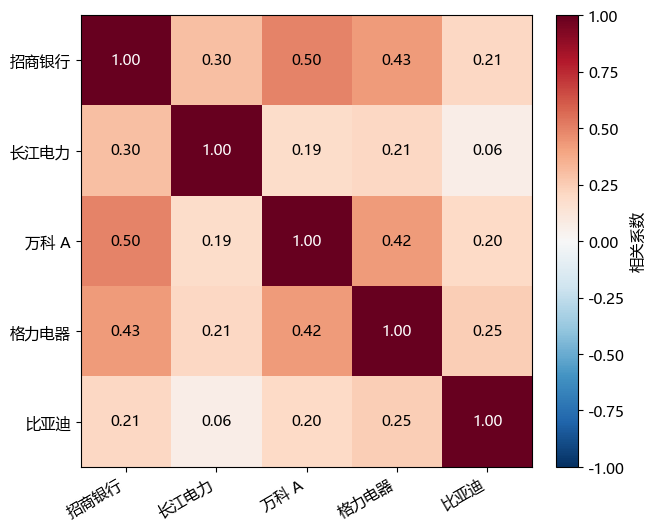

In [34]:
#| label: fig-mc-nb-portfolio-correlation
#| fig-cap: "五只股票的日收益相关系数；主对角线为 1。"
portfolio_values = portfolio_returns.to_numpy()
portfolio_mu = portfolio_values.mean(axis=0)
portfolio_cov = np.cov(portfolio_values, rowvar=False, ddof=1)
assert np.linalg.eigvalsh(portfolio_cov).min() > 0
display(pd.Series(portfolio_mu, index=stock_names, name='平均日收益率'))
display(pd.DataFrame(portfolio_cov, index=stock_names, columns=stock_names))
fig, axis = plt.subplots(figsize=(6.4, 5.2), layout='constrained')
correlations = portfolio_returns.corr().to_numpy()
picture = axis.imshow(correlations, vmin=-1, vmax=1, cmap='RdBu_r')
axis.set_xticks(range(5), stock_names, rotation=30, ha='right')
axis.set_yticks(range(5), stock_names)
for row in range(5):
    for column in range(5):
        axis.text(column, row, f'{correlations[row, column]:.2f}', ha='center', va='center',
                  color='white' if abs(correlations[row, column]) > .65 else 'black')
fig.colorbar(picture, ax=axis, label='相关系数')
plt.show()

### 两种生成方式保留什么 {.unnumbered}

正态模拟从历史估计的联合分布抽取收益，不是人为另定均值和协方差。整行重抽样则直接抽取某个历史交易日的五个收益，同时保留当天股票间的联系。两种方法各生成 100000 组单日收益，再按同一组权重计算组合收益。

这一步只比较单日分布，并不保留跨日联系。多日持有期将在区块部分单独处理。

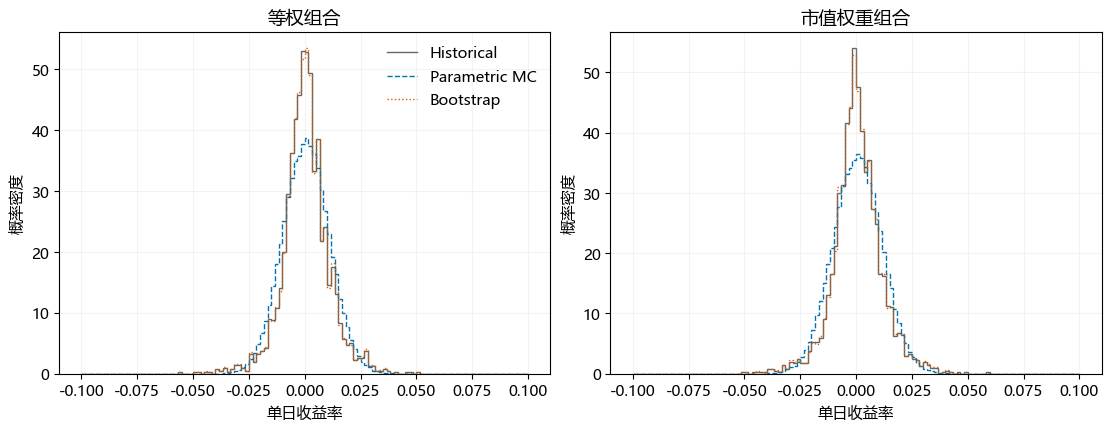

In [35]:
#| label: fig-mc-nb-portfolio-distributions
#| fig-cap: "同一组权重下的历史、正态模拟与整行重抽样单日组合收益分布。"
portfolio_B = 100000
portfolio_normal_rng = np.random.default_rng(SEED)
portfolio_boot_rng = np.random.default_rng(SEED + 1)
portfolio_normal = portfolio_normal_rng.multivariate_normal(portfolio_mu, portfolio_cov, size=portfolio_B)
portfolio_rows = portfolio_boot_rng.integers(0, len(portfolio_values), size=portfolio_B)
portfolio_boot = portfolio_values[portfolio_rows]
portfolio_arrays = {
    'Historical': portfolio_values @ portfolio_weights,
    'Parametric MC': portfolio_normal @ portfolio_weights,
    'Bootstrap': portfolio_boot @ portfolio_weights,
}
np.savez_compressed(OUTPUT / 'portfolio-single-day.npz', **portfolio_arrays)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, layout='constrained')
distribution_edges = np.linspace(-.10, .10, 121)
for column, axis in enumerate(axes):
    for method, color, style in [('Historical', '#666666', '-'), ('Parametric MC', '#0072B2', '--'), ('Bootstrap', '#D55E00', ':')]:
        values = portfolio_arrays[method][:, column]
        counts, edges = np.histogram(values, bins=distribution_edges)
        axis.stairs(counts / len(values) / np.diff(edges), edges, label=method, color=color, linestyle=style)
    axis.set(title=portfolio_names[column], xlabel='单日收益率', ylabel='概率密度')
    axis.grid(alpha=.15)
axes[0].legend(frameon=False)
plt.show()

### 用 VaR 与 ES 比较尾部损失 {.unnumbered}

将损失定义为收益率的相反数，95% VaR 是损失分布的 95% 分位数，95% ES 是最差 5% 概率质量内的平均损失。样本数乘尾部概率不为整数时，边界观测按相应份额计权。以下表图均为单日损失率，表中换算为百分比。

,portfolio,method,95% VaR (%),95% ES (%)
0,Equal-weight,Historical,1.593031,2.392513
1,Value-weight,Historical,1.665616,2.480867
2,Equal-weight,Parametric MC,1.680592,2.120024
3,Value-weight,Parametric MC,1.751311,2.216157
4,Equal-weight,Bootstrap,1.596668,2.420712
5,Value-weight,Bootstrap,1.671404,2.510128


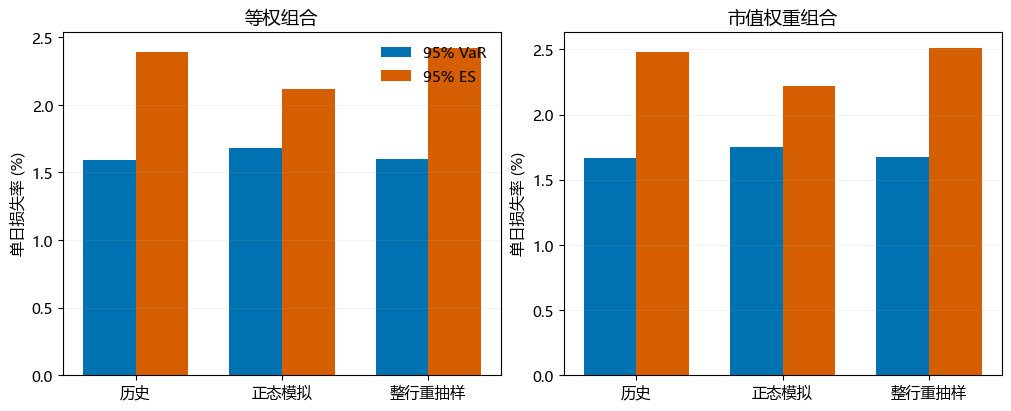

In [36]:
#| label: fig-mc-nb-portfolio-risk
#| fig-cap: "95% 单日 VaR 与 ES，损失率以百分比表示。"
def portfolio_risk(values, alpha=.05):
    # 固定最差alpha的经验概率质量，不因相同取值而扩大尾部。
    losses = -np.asarray(values)
    ordered = np.sort(losses)[::-1]
    mass = len(losses) * alpha
    count = int(np.floor(mass))
    fraction = mass - count
    tail_sum = ordered[:count].sum()
    if fraction > 0:
        tail_sum += fraction * ordered[count]
    return float(np.quantile(losses, 1 - alpha)), float(tail_sum / mass)

portfolio_risk_rows = []
for method, values in portfolio_arrays.items():
    for column, portfolio in enumerate(['Equal-weight', 'Value-weight']):
        value95, es95 = portfolio_risk(values[:, column])
        value99, es99 = portfolio_risk(values[:, column], .01)
        portfolio_risk_rows.append({'portfolio': portfolio, 'method': method,
                                    'VaR_95': value95, 'ES_95': es95, 'VaR_99': value99, 'ES_99': es99})
portfolio_risks = pd.DataFrame(portfolio_risk_rows)
portfolio_risks.to_csv(OUTPUT / 'portfolio-risk-metrics.csv', index=False, encoding='utf-8-sig')
portfolio_main = portfolio_risks[['portfolio', 'method', 'VaR_95', 'ES_95']].copy()
portfolio_main[['VaR_95', 'ES_95']] *= 100
display(portfolio_main.rename(columns={'VaR_95': '95% VaR (%)', 'ES_95': '95% ES (%)'}))
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout='constrained')
for column, portfolio in enumerate(['Equal-weight', 'Value-weight']):
    subset = portfolio_main[portfolio_main.portfolio == portfolio].set_index('method')
    positions = np.arange(3)
    axes[column].bar(positions-.18, subset.VaR_95, width=.36, label='95% VaR', color='#0072B2')
    axes[column].bar(positions+.18, subset.ES_95, width=.36, label='95% ES', color='#D55E00')
    axes[column].set_xticks(positions, ['历史', '正态模拟', '整行重抽样'])
    axes[column].set(title=portfolio_names[column], ylabel='单日损失率 (%)')
    axes[column].grid(axis='y', alpha=.15)
axes[0].legend(frameon=False)
plt.show()

历史与正态模拟的 VaR 可能较接近，但 ES 仍可能有明显区别。应分别观察损失分位点与尾部平均损失，不能仅凭均值、方差接近就认为尾部风险也一致。

### 用区块抽样模拟多日组合收益 {.unnumbered #sec-mc-nb-block}

[返回正文：多日区块抽样](../../lectures/monte-carlo.qmd#sec-mc-portfolio)。

持有期限固定为 20 个交易日，期初按等权或市值权重配置，期间不调仓。区块长度取 5、10、20 日。候选窗口逐日移动且允许重叠，仅保留窗口内五只股票收益均有效的记录。

每种长度分别建立独立整行抽样对照，其日收益池由当前全部有效区块展开得到，保留窗口重叠引起的抽样权重。两种方式因而具有相同的单日经验抽样分布，区别主要在于是否成段保留连续记录。不同长度的有效窗口略有差异，应先在相同长度内比较。

先将每只股票逐日收益连乘得到期末价值，再按期初权重加总。不能把单日风险乘以根号 20，或把权重改为每天再平衡来替代这个实验。

In [37]:
def block_risk_metrics(values):
    ordered = np.sort(-values)[::-1]
    mass = len(values) * .05
    count = int(np.floor(mass))
    fraction = mass - count
    tail_sum = ordered[:count].sum()
    if fraction:
        tail_sum += fraction * ordered[count]
    return dict(mean=values.mean(), sd=values.std(ddof=1), q05=np.quantile(values, .05),
                VaR95=np.quantile(-values, .95), ES95=tail_sum / mass)

block_values = portfolio_returns.reindex(portfolio_prices.index).to_numpy()
block_horizon = 20
block_records, block_support, block_saved = [], [], {}
for block_length in [5, 10, 20]:
    starts = np.array([start for start in range(len(block_values)-block_length+1)
                       if np.isfinite(block_values[start:start+block_length]).all()])
    blocks = np.stack([block_values[start:start+block_length] for start in starts])
    assert block_horizon % block_length == 0 and np.isfinite(blocks).all()
    covered = np.unique((starts[:, None] + np.arange(block_length)).ravel())
    pool = blocks.reshape(-1, len(portfolio_returns.columns))
    block_support.append(dict(L=block_length, blocks=len(blocks), covered_days=len(covered), pool_size=len(pool)))
    for repetitions in [10000, 100000]:
        for seed in [20261017, 20261018, 20261019]:
            for method in ['iid', 'block']:
                # 保留原种子组合及分批大小，合并不会改变抽样次序。
                block_rng = np.random.default_rng(np.random.SeedSequence([seed, block_length, method == 'block']))
                outcomes = []
                for offset in range(0, repetitions, 10000):
                    batch = min(10000, repetitions-offset)
                    if method == 'block':
                        selected = block_rng.integers(len(blocks), size=(batch, block_horizon//block_length))
                        paths = blocks[selected].reshape(batch, block_horizon, len(portfolio_returns.columns))
                    else:
                        selected = block_rng.integers(len(pool), size=(batch, block_horizon))
                        paths = pool[selected]
                    outcomes.append(np.prod(1+paths, axis=1) @ portfolio_weights - 1)
                outcomes = np.concatenate(outcomes)
                assert outcomes.shape == (repetitions, 2) and np.isfinite(outcomes).all()
                for column, name in enumerate(portfolio_names):
                    block_records.append(dict(L=block_length, B=repetitions, seed=seed, method=method,
                                              portfolio=name, **block_risk_metrics(outcomes[:, column])))
                if repetitions == 100000 and seed == 20261017:
                    block_saved[f'L{block_length}_{method}'] = outcomes

block_metrics = pd.DataFrame(block_records)
block_main = block_metrics.query('B == 100000 and seed == 20261017')
block_metrics.to_csv(OUTPUT / 'block-metrics-all.csv', index=False, encoding='utf-8-sig')
np.savez_compressed(OUTPUT / 'block-returns.npz', **block_saved)
pd.DataFrame(block_support).to_csv(OUTPUT / 'block-support.csv', index=False, encoding='utf-8-sig')
block_display = []
for name in portfolio_names:
    for length in [5, 10, 20]:
        subset = block_main[(block_main.portfolio == name) & (block_main.L == length)].set_index('method')
        block_display.append({'组合': name, '区块长度': length,
                              '独立 VaR (%)': subset.loc['iid', 'VaR95']*100,
                              '区块 VaR (%)': subset.loc['block', 'VaR95']*100,
                              '独立 ES (%)': subset.loc['iid', 'ES95']*100,
                              '区块 ES (%)': subset.loc['block', 'ES95']*100})
display(pd.DataFrame(block_display).round(2))

,组合,区块长度,独立 VaR (%),区块 VaR (%),独立 ES (%),区块 ES (%)
0,等权组合,5,6.78,6.67,8.66,8.73
1,等权组合,10,6.76,6.38,8.60,8.79
2,等权组合,20,6.81,6.08,8.71,7.98
3,市值权重组合,5,6.83,6.68,8.76,8.69
4,市值权重组合,10,6.81,6.56,8.71,8.80
5,市值权重组合,20,6.86,6.26,8.80,8.11


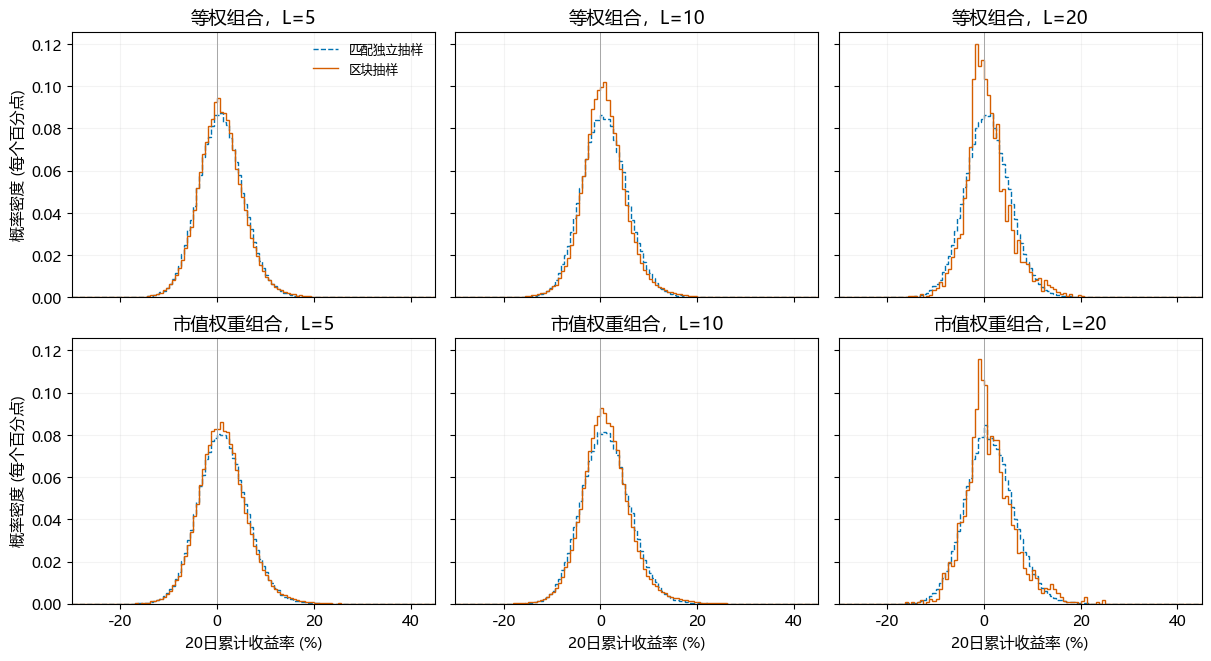

In [38]:
#| label: fig-mc-nb-block-distributions
#| fig-cap: "每组 100000 条 20 日买入持有路径；各面板坐标和分箱一致。"
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5), sharex=True, sharey=True, layout='constrained')
block_edges = np.linspace(-30, 45, 121)
for column, length in enumerate([5, 10, 20]):
    for portfolio, name in enumerate(portfolio_names):
        axis = axes[portfolio, column]
        for method, color, style, label in [('iid', '#0072B2', '--', '匹配独立抽样'), ('block', '#D55E00', '-', '区块抽样')]:
            values = block_saved[f'L{length}_{method}'][:, portfolio] * 100
            counts, edges = np.histogram(values, bins=block_edges)
            axis.stairs(counts/len(values)/np.diff(edges), edges, color=color, linestyle=style, label=label)
        axis.set(title=f'{name}，L={length}', xlim=(-30, 45))
        axis.axvline(0, color='.65', linewidth=.7)
        axis.grid(alpha=.15)
        if portfolio == 1:
            axis.set_xlabel('20日累计收益率 (%)')
        if column == 0:
            axis.set_ylabel('概率密度 (每个百分点)')
axes[0, 0].legend(frameon=False, fontsize=9)
plt.show()

L=10 时，等权组合区块抽样的 VaR 约为 6.38%，ES 约为 8.79%。与匹配独立抽样比较，VaR 较低而 ES 较高，说明两项指标需要分别阅读。保留连续关系不必然提高风险估计，也不能因某个长度得到较低风险就认定它最合适。

::: {.callout-note collapse="true" title="案例三完整指标、窗口与稳定性核验"}

以下保留 72 组区块指标、有效窗口、自相关和 L=20 完整窗口枚举。单日正态模拟的解析基准及忽略相关性的方差对照也在这里核对。表中原始风险值为收益率，正文与主表另乘 100 显示。

In [39]:
with pd.option_context('display.max_rows', None):
    display(block_metrics)
display(pd.DataFrame(block_support))
display(block_metrics.groupby(['B', 'L', 'method', 'portfolio'])[['VaR95', 'ES95']].agg(['min', 'max']))
block_acf = []
for lag in [1, 5, 10, 20]:
    for stock in portfolio_returns.columns:
        series = pd.Series(block_values[:, list(portfolio_returns.columns).index(stock)], index=portfolio_prices.index)
        block_acf.append({'stock': stock, 'lag': lag, 'return_acf': series.autocorr(lag),
                          'squared_return_acf': series.pow(2).autocorr(lag)})
display(pd.DataFrame(block_acf))
exact_blocks = np.stack([block_values[start:start+20] for start in range(len(block_values)-19)
                         if np.isfinite(block_values[start:start+20]).all()])
exact_returns = np.prod(1+exact_blocks, axis=1) @ portfolio_weights - 1
exact_table = pd.DataFrame([{'portfolio': name, **block_risk_metrics(exact_returns[:, column])}
                            for column, name in enumerate(portfolio_names)])
exact_table.to_csv(OUTPUT / 'block-L20-exact.csv', index=False, encoding='utf-8-sig')
display(exact_table)
analytic_rows = []
for column, name in enumerate(portfolio_names):
    weights = portfolio_weights[:, column]
    mean = portfolio_mu @ weights
    deviation = np.sqrt(weights @ portfolio_cov @ weights)
    analytic_rows.append({'组合': name, '解析正态95%VaR': -mean+norm.ppf(.95)*deviation,
                          '解析正态95%ES': -mean+norm.pdf(norm.ppf(.95))/.05*deviation,
                          '忽略相关性标准差': np.sqrt(weights @ np.diag(np.diag(portfolio_cov)) @ weights),
                          '保留相关性标准差': deviation})
display(pd.DataFrame(analytic_rows))
portfolio_stability = []
for stability_seed in [SEED+10, SEED+20, SEED+30]:
    normal_rng = np.random.default_rng(stability_seed)
    bootstrap_rng = np.random.default_rng(stability_seed+1)
    normal_paths = normal_rng.multivariate_normal(portfolio_mu, portfolio_cov, size=500000) @ portfolio_weights
    bootstrap_paths = portfolio_values[bootstrap_rng.integers(0, len(portfolio_values), size=500000)] @ portfolio_weights
    for size in [10000, 50000, 100000, 500000]:
        for method, values in [('Parametric MC', normal_paths), ('Bootstrap', bootstrap_paths)]:
            for column, name in enumerate(['Equal-weight', 'Value-weight']):
                value95, es95 = portfolio_risk(values[:size, column])
                portfolio_stability.append({'seed': stability_seed, 'B': size, 'portfolio': name,
                                            'method': method, 'VaR_95': value95, 'ES_95': es95})
portfolio_stability = pd.DataFrame(portfolio_stability)
portfolio_stability.to_csv(OUTPUT / 'portfolio-stability.csv', index=False, encoding='utf-8-sig')
display(portfolio_stability.groupby(['B', 'portfolio', 'method'])[['VaR_95', 'ES_95']].agg(['min', 'max']))
case_results['portfolio'] = {'daily_risk_rows': len(portfolio_risks), 'block_metric_rows': len(block_metrics),
                              'sample_rows': len(portfolio_returns), 'block_support': block_support}

,L,B,seed,method,portfolio,mean,sd,q05,VaR95,ES95
0,5,10000,20261017,iid,等权组合,0.008133,0.046778,-0.066637,0.066637,0.085353
1,5,10000,20261017,iid,市值权重组合,0.011593,0.049617,-0.067685,0.067685,0.086846
2,5,10000,20261017,block,等权组合,0.007698,0.047184,-0.065870,0.065870,0.087353
3,5,10000,20261017,block,市值权重组合,0.011349,0.050419,-0.067597,0.067597,0.088264
4,5,10000,20261018,iid,等权组合,0.007431,0.047129,-0.067970,0.067970,0.087972
5,5,10000,20261018,iid,市值权重组合,0.011466,0.049963,-0.068498,0.068498,0.088019
6,5,10000,20261018,block,等权组合,0.008393,0.047198,-0.066426,0.066426,0.087509
7,5,10000,20261018,block,市值权重组合,0.012188,0.050109,-0.066480,0.066480,0.086067
8,5,10000,20261019,iid,等权组合,0.007943,0.047503,-0.066713,0.066713,0.086334
9,5,10000,20261019,iid,市值权重组合,0.011499,0.050474,-0.067187,0.067187,0.086895


,L,blocks,covered_days,pool_size
0,5,2353,2397,11765
1,10,2300,2390,23000
2,20,2200,2390,44000


VaR95                ES95          
                                 min       max       min       max
B      L  method portfolio                                        
10000  5  block  市值权重组合     0.066480  0.067755  0.086067  0.088264
                 等权组合       0.065870  0.067637  0.087353  0.088283
          iid    市值权重组合     0.067187  0.068498  0.086846  0.088019
                 等权组合       0.066637  0.067970  0.085353  0.087972
       10 block  市值权重组合     0.065421  0.066662  0.088547  0.089798
                 等权组合       0.063444  0.065421  0.088096  0.089089
          iid    市值权重组合     0.067842  0.069520  0.086547  0.089135
                 等权组合       0.067449  0.069292  0.085260  0.087168
       20 block  市值权重组合     0.062373  0.062665  0.079976  0.081685
                 等权组合       0.059616  0.060805  0.078862  0.079821
          iid    市值权重组合     0.067171  0.069099  0.086225  0.090006
                 等权组合       0.067205  0.069241  0.085725  0.088810
100000 5  block  市值权重组合     0.066022  0.066833  0.085917  0.086873
                 等权组合       0.066035  0.066904  0.086630  0.087514
          iid    市值权重组合     0.067799  0.068277  0.087169  0.087645
                 等权组合       0.067430  0.067808  0.086066  0.086636
       10 block  市值权重组合     0.065336  0.065885  0.087598  0.088600
                 等权组合       0.063786  0.064216  0.087578  0.088592
          iid    市值权重组合     0.068117  0.068902  0.087103  0.088349
                 等权组合       0.067640  0.068463  0.086028  0.087169
       20 block  市值权重组合     0.062504  0.062605  0.080141  0.081089
                 等权组合       0.059696  0.060780  0.079006  0.079802
          iid    市值权重组合     0.068546  0.068656  0.088014  0.088878
                 等权组合       0.068098  0.068276  0.087068  0.087422

,stock,lag,return_acf,squared_return_acf
0,600036,1,-0.005846,0.157270
1,600900,1,-0.074328,0.136624
2,000002,1,0.026501,0.204061
3,000651,1,0.006368,0.168704
4,002594,1,0.002366,0.097378
5,600036,5,-0.027534,0.095891
6,600900,5,0.006624,0.041374
7,000002,5,-0.010714,0.119256
8,000651,5,-0.070276,0.121782
9,002594,5,-0.027645,0.099101


,portfolio,mean,sd,q05,VaR95,ES95
0,等权组合,0.007209,0.045175,-0.060750,0.060750,0.079670
1,市值权重组合,0.011315,0.050076,-0.062608,0.062608,0.080732


,组合,解析正态95%VaR,解析正态95%ES,忽略相关性标准差,保留相关性标准差
0,等权组合,0.016775,0.021135,0.007479,0.010433
1,市值权重组合,0.017553,0.022155,0.009150,0.011013


VaR_95               ES_95          
                                        min       max       min       max
B      portfolio    method                                               
10000  Equal-weight Bootstrap      0.015460  0.015928  0.022649  0.023962
                    Parametric MC  0.016466  0.016799  0.020692  0.021079
       Value-weight Bootstrap      0.015621  0.016581  0.023511  0.024707
                    Parametric MC  0.017245  0.017775  0.021624  0.022205
50000  Equal-weight Bootstrap      0.015828  0.016020  0.023835  0.023919
                    Parametric MC  0.016544  0.016801  0.020946  0.021069
       Value-weight Bootstrap      0.016581  0.016815  0.024648  0.024889
                    Parametric MC  0.017416  0.017597  0.022032  0.022127
100000 Equal-weight Bootstrap      0.015939  0.015967  0.023841  0.023884
                    Parametric MC  0.016690  0.016898  0.021035  0.021127
       Value-weight Bootstrap      0.016642  0.016763  0.024755  0.024785
                    Parametric MC  0.017521  0.017579  0.022109  0.022172
500000 Equal-weight Bootstrap      0.015939  0.015967  0.023912  0.023925
                    Parametric MC  0.016717  0.016774  0.021050  0.021105
       Value-weight Bootstrap      0.016714  0.016763  0.024819  0.024865
                    Parametric MC  0.017532  0.017568  0.022098  0.022129

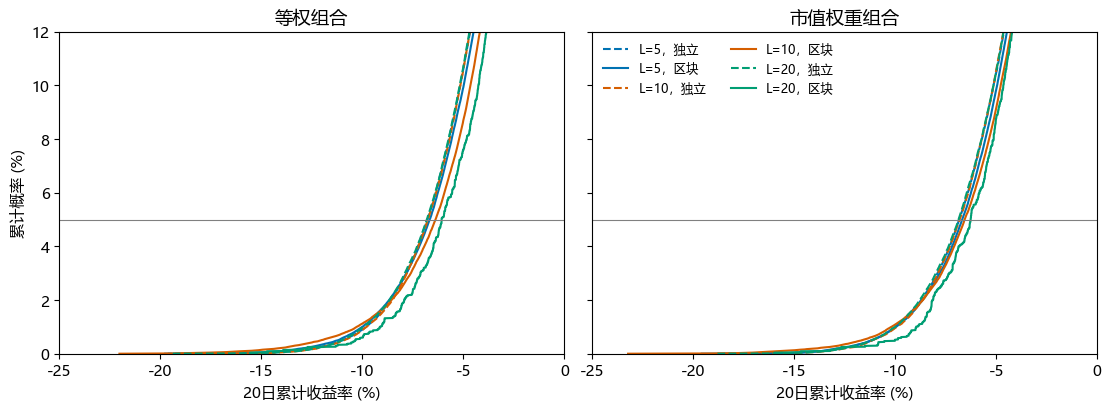

In [40]:
#| label: fig-mc-nb-block-tail
#| fig-cap: "左尾经验分布。5% 横线对应的收益率取负可读出 95% VaR。"
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, layout='constrained')
for portfolio, name in enumerate(portfolio_names):
    for length, color in [(5, '#0072B2'), (10, '#D55E00'), (20, '#009E73')]:
        for method, style in [('iid', '--'), ('block', '-')]:
            values = np.sort(block_saved[f'L{length}_{method}'][:, portfolio]) * 100
            indices = np.arange(0, int(len(values)*.12), 10)
            axes[portfolio].plot(values[indices], (indices+1)/len(values)*100, color=color, linestyle=style,
                                  label=f'L={length}，' + ('区块' if method == 'block' else '独立'))
    axes[portfolio].axhline(5, color='.5', linewidth=.8)
    axes[portfolio].set(title=name, xlabel='20日累计收益率 (%)', xlim=(-25, 0), ylim=(0, 12))
axes[0].set_ylabel('累计概率 (%)')
axes[1].legend(frameon=False, fontsize=9, ncol=2)
plt.show()

:::

## 案例四：从随机变量到随机过程 {.unnumbered #sec-mc-nb-process}

[返回正文：案例四](../../lectures/monte-carlo.qmd#sec-mc-process)。

本例关注期末上涨与途中跌破阈值两类事件。二者都从价格路径计算，但回答不同问题。下面依次用随机游走说明冲击累积、用布朗运动说明时间尺度，再用 GBM 保持价格为正。

### 随机游走 {.unnumbered}

每一步给前值增加一个独立冲击，从 0 开始逐步累加。该例的横轴是离散步数，冲击标准差设为 1，不把它误当作已经按年化尺度设置的资产收益模型。

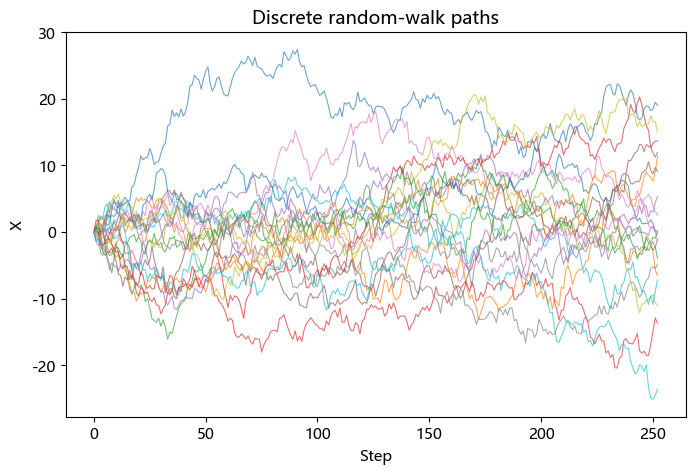

In [41]:
#| label: fig-mc-nb-random-walk
#| fig-cap: "独立冲击逐步累积形成的随机游走路径。"
rng = np.random.default_rng(SEED)
T_steps = 252
n_paths = 20
eps = rng.normal(0, 1, size=(n_paths, T_steps))
paths = np.c_[np.zeros(n_paths), np.cumsum(eps, axis=1)]
fig, ax = plt.subplots(figsize=(8,5))
for row in paths:
    ax.plot(row, linewidth=0.8, alpha=0.65)
ax.set_xlabel("Step"); ax.set_ylabel("X"); ax.set_title("Discrete random-walk paths")
plt.show()

### 布朗运动 {.unnumbered}

在一年划分 252 个时间步的网格上，布朗增量方差为每步长度 $\Delta t$，标准差为 $\sqrt{\Delta t}$。不重叠区间的增量独立。下图展示 20 条路径，后面单独抽取 100000 个终点检查均值与标准差。

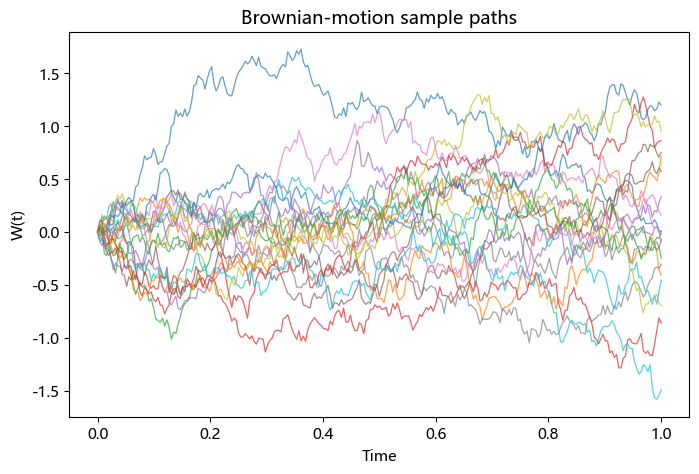

In [42]:
#| label: fig-mc-nb-brownian
#| fig-cap: "一年时间网格上的布朗运动路径。"
T = 1.0
N = 252
dt = T / N
rng = np.random.default_rng(SEED)
dW = rng.normal(0, np.sqrt(dt), size=(20, N))
W = np.c_[np.zeros(20), np.cumsum(dW, axis=1)]
t = np.linspace(0, T, N + 1)
fig, ax = plt.subplots(figsize=(8,5))
for row in W:
    ax.plot(t, row, linewidth=0.9, alpha=0.7)
ax.set_xlabel("Time"); ax.set_ylabel("W(t)"); ax.set_title("Brownian-motion sample paths")
plt.show()

In [43]:
rng = np.random.default_rng(SEED)
WT = rng.normal(0, np.sqrt(T), size=100000)
pd.Series({
    "mean_WT": WT.mean(),
    "sd_WT": WT.std(ddof=1),
    "theoretical_mean": 0.0,
    "theoretical_sd": np.sqrt(T),
})

mean_WT            -0.002359
sd_WT               1.000235
theoretical_mean    0.000000
theoretical_sd      1.000000
dtype: float64

### 几何布朗运动 {.unnumbered}

GBM 通过对数价格的变化生成价格路径。漂移率为 0.08，下面分别取年化波动率 0.10 和 0.35，各画 30 条路径。两组使用不同种子，不能将图中任意两条线当作共用冲击的配对比较。指数表达式计算的是网格上的精确转移，不是 Euler 价格更新。

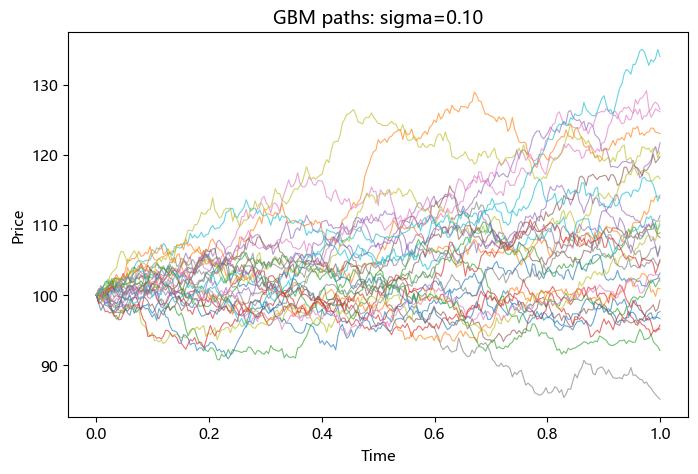

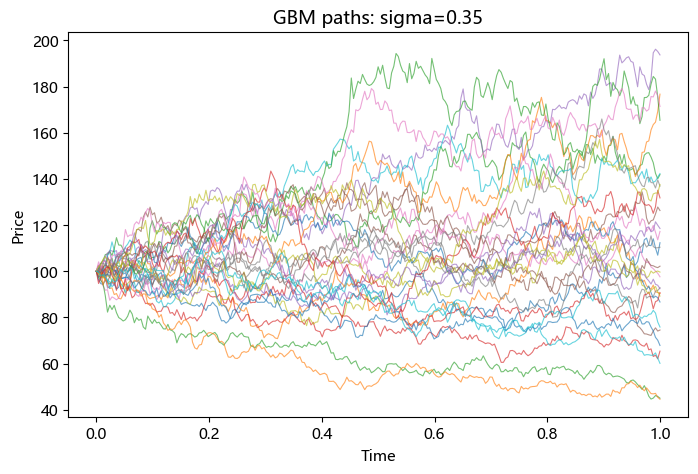

In [44]:
#| label: fig-mc-nb-gbm
#| fig-cap: ["较低年化波动率下的 GBM 路径。", "较高年化波动率下的 GBM 路径。"]
def gbm_paths(S0=100, mu=0.08, sigma=0.2, T=1.0, N=252, n_paths=50, seed=SEED):
    rng = np.random.default_rng(seed)
    dt = T / N
    dW = rng.normal(0, np.sqrt(dt), size=(n_paths, N))
    W = np.c_[np.zeros(n_paths), np.cumsum(dW, axis=1)]
    t = np.linspace(0, T, N + 1)
    S = S0 * np.exp((mu - 0.5*sigma**2)*t[None,:] + sigma*W)
    return t, S

for sigma in [0.10, 0.35]:
    t, S = gbm_paths(sigma=sigma, n_paths=30, seed=SEED + int(sigma*1000))
    fig, ax = plt.subplots(figsize=(8,5))
    for row in S:
        ax.plot(t, row, linewidth=0.8, alpha=0.65)
    ax.set_xlabel("Time"); ax.set_ylabel("Price")
    ax.set_title(f"GBM paths: sigma={sigma:.2f}")
    plt.show()

### 终值风险和路径风险 {.unnumbered}

主风险实验单独设定初始价格 100 元、漂移率 0.08、波动率 0.30、期限 1 年、252 步、5000 条路径，阈值为 75 元。三个事件分别是期末价格高于 100、网格价格曾严格低于 75，以及两者同时发生。下面补齐各事件的计数，概率分母全部为 5000。

这不是止损交易模拟，也不是最大回撤。统计仅监测离散网格时点，不保证捕捉时点之间的连续越界。

In [45]:
S0=100; mu=0.08; sigma=0.30; T=1; N=252; n_paths=5000; barrier=75
t, S = gbm_paths(S0=S0, mu=mu, sigma=sigma, T=T, N=N, n_paths=n_paths, seed=SEED)
terminal = S[:, -1]
hit_barrier = (S.min(axis=1) < barrier)
pd.Series({
    "P(S_T > S0)": np.mean(terminal > S0),
    "P(path ever falls below barrier)": np.mean(hit_barrier),
    "P(S_T > S0 AND path hit barrier)": np.mean((terminal > S0) & hit_barrier),
})

P(S_T > S0)                         0.5498
P(path ever falls below barrier)    0.2804
P(S_T > S0 AND path hit barrier)    0.0266
dtype: float64

In [46]:
path_events = pd.DataFrame({
    '事件': ['期末上涨', '网格中曾跌破75', '期末上涨且网格中曾跌破75'],
    '计数': [int((terminal > S0).sum()), int(hit_barrier.sum()), int(((terminal > S0) & hit_barrier).sum())],
})
path_events['分母'] = n_paths
path_events['概率 (%)'] = path_events['计数'] / n_paths * 100
display(path_events)
path_events.to_csv(OUTPUT / 'path-events.csv', index=False, encoding='utf-8-sig')
case_results['path_risk'] = {'B': int(n_paths), 'counts': path_events['计数'].tolist(),
                             'parameters': {'S0': float(S0), 'mu': float(mu), 'sigma': float(sigma),
                                             'T': float(T), 'N': int(N), 'barrier': float(barrier)}}

,事件,计数,分母,概率 (%)
0,期末上涨,2749,5000,54.98
1,网格中曾跌破75,1402,5000,28.04
2,期末上涨且网格中曾跌破75,133,5000,2.66


期末上涨的路径仍可能在途中跌破 75 元。按本页设定，两类单独事件和联合事件分别约为 54.98%、28.04% 和 2.66%。第三项不是以期末上涨路径为分母的条件概率。

::: {.callout-note collapse="true" title="扩展阅读：Monte Carlo 期权定价"}

欧式看涨期权到期支付为 $\max(S_{T}-K,0)$，只与终值有关，因此本例直接模拟终值，不必生成完整路径。风险中性分布的漂移使用无风险利率，不能将其中的上涨概率解释为现实发生概率。

本段独立设置初始价与执行价均为 100 元、连续复利无风险年利率 0.05、年化波动率 0.20、期限 1 年。参数与上面的路径风险实验不同。先计算折现支付的平均值，再用其标准差除以样本数平方根得到 MC 标准误，并与同一模型下的 Black–Scholes 闭式价格比较。

In [47]:
def normal_cdf(x):
    return 0.5 * (1 + erf(x / sqrt(2)))

def bs_call_price(S0, K, r, sigma, T):
    d1 = (log(S0/K)+(r+0.5*sigma**2)*T)/(sigma*sqrt(T))
    d2 = d1 - sigma*sqrt(T)
    return S0*normal_cdf(d1) - K*exp(-r*T)*normal_cdf(d2)

def mc_call_price(S0, K, r, sigma, T, B, seed=SEED):
    rng = np.random.default_rng(seed)
    Z = rng.normal(size=B)
    ST = S0*np.exp((r-0.5*sigma**2)*T + sigma*np.sqrt(T)*Z)
    payoff = np.maximum(ST-K, 0)
    return np.exp(-r*T)*payoff.mean()

S0=100; K=100; r=0.05; sigma=0.20; T=1.0
bs_price = bs_call_price(S0,K,r,sigma,T)
mc_price = mc_call_price(S0,K,r,sigma,T,B=100000)
pd.Series({
    "Black-Scholes closed-form": bs_price,
    "Monte Carlo estimate": mc_price,
    "MC minus BS": mc_price - bs_price,
})

Black-Scholes closed-form    10.450584
Monte Carlo estimate         10.416516
MC minus BS                  -0.034067
dtype: float64

In [48]:
pricing_B = 100000
pricing_rng = np.random.default_rng(SEED)
pricing_shocks = pricing_rng.normal(size=pricing_B)
pricing_terminal = S0 * np.exp((r-.5*sigma**2)*T + sigma*np.sqrt(T)*pricing_shocks)
discounted_payoff = np.exp(-r*T) * np.maximum(pricing_terminal-K, 0)
pricing_mcse = discounted_payoff.std(ddof=1) / np.sqrt(pricing_B)
assert np.isclose(discounted_payoff.mean(), mc_price)
display(pd.Series({'MC价格': mc_price, '闭式价格': bs_price, 'MC标准误': pricing_mcse,
                   'MC减闭式': mc_price-bs_price}))
case_results['option'] = {'MC': float(mc_price), 'closed_form': float(bs_price), 'MCSE': float(pricing_mcse)}

MC价格     10.416516
闭式价格     10.450584
MC标准误     0.046336
MC减闭式    -0.034067
dtype: float64

In [49]:
B_grid = [100,500,1000,5000,10000,50000,100000]
rows=[]
for B in B_grid:
    p = mc_call_price(S0,K,r,sigma,T,B=B,seed=SEED)
    rows.append({"B":B,"MC_price":p,"error_vs_BS":p-bs_price})
conv = pd.DataFrame(rows)
conv

,B,MC_price,error_vs_BS
0,100,13.639128,3.188544
1,500,10.855077,0.404494
2,1000,10.565390,0.114806
3,5000,10.510013,0.059430
4,10000,10.516213,0.065630
5,50000,10.449630,-0.000953
6,100000,10.416516,-0.034067


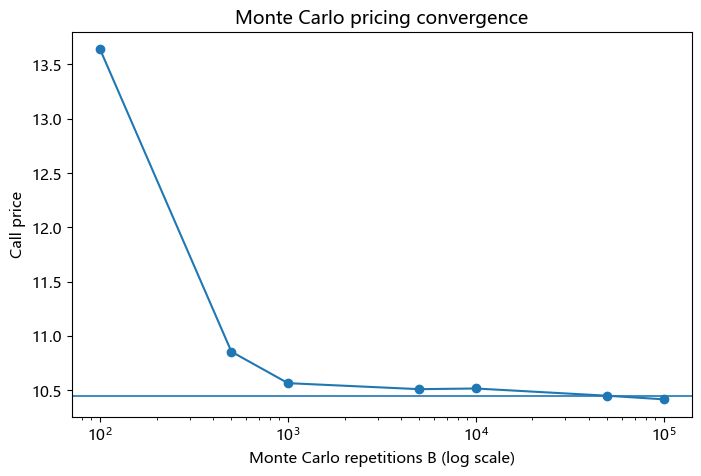

In [50]:
#| label: fig-mc-nb-option-convergence
#| fig-cap: "不同重复次数下 MC 价格与闭式价格比较，误差不要求单调下降。"
fig, ax = plt.subplots(figsize=(8,5))
ax.plot(conv["B"], conv["MC_price"], marker="o")
ax.axhline(bs_price, linewidth=1.2)
ax.set_xscale("log")
ax.set_xlabel("Monte Carlo repetitions B (log scale)")
ax.set_ylabel("Call price")
ax.set_title("Monte Carlo pricing convergence")
plt.show()

本参数下 MC 价格约为 10.4165，闭式价格约为 10.4506，MC 标准误约为 0.0463。这个对照用于核验计算，并不证明真实资产价格符合 GBM。

:::

## 结果保存与返回正文 {.unnumbered #sec-mc-nb-output}

本页各案例的参数和随机数设置相互明确区分。完整结果文件保存在开头指定的输出目录，不改输入数据。课前从头运行并保存 Notebook，课堂可以直接通过目录跳转阅读，不需要现场重新计算。

[返回理论正文](../../lectures/monte-carlo.qmd)。模型选择、设计检查和全章总结仍以理论章为主，不在这里重复展开。

In [51]:
(OUTPUT / 'run-summary.json').write_text(json.dumps(case_results, ensure_ascii=False, indent=2), encoding='utf-8')
display(pd.DataFrame([{'案例': name, '已保存': True} for name in case_results]))

,案例,已保存
0,case1,True
1,valuation,True
2,portfolio,True
3,path_risk,True
4,option,True
